In [4]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
import os

os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

In [6]:
import json
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import dask
import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import rioxarray as rxr
import seaborn as sns
import xarray as xr
from dask.diagnostics import ProgressBar

from cordex2energy.conversion_energy.demand import (
    normalize_population_data,
    process_population_data,
)
from cordex2energy.conversion_energy.land_eligibility import compute_eligibility
from cordex2energy.conversion_energy.power_density import (
    pv_power_density,
    wind_power_density,
)
from cordex2energy.conversion_energy.pv import ROOFTOP_PV_CONFIGURATION
from cordex2energy.conversion_energy.wind import EUROPE_HUB_HEIGHTS
from cordex2energy.results.plotting import (
    BLUE,
    RED,
    apply_land_mask,
    plot_ensemble_mean,
    plot_ensemble_mean_change,
    plot_percentage_change_spread,
    plot_yearly_timeseries_ensemble,
    plot_yearly_timeseries_ensemble_mean_range,
)
from cordex2energy.utils.constants import (
    EUROPE_TURBINES,
    EXTENT_BC,
    EXTENT_CH,
    IPCC_LINE_CHART_COLOR_PALETTE_HEX,
)
from cordex2energy.utils.utils_xarray import cell_area_km2, sel_extent

sns.set_style("whitegrid", {"grid.color": ".93"})

In [7]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"
path_data_temporary = Path(paths["path_data_temporary"])

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

path_figs = Path(paths["path_figs"])

In [8]:
extent = {"lat_min": 30, "lat_max": 72.6, "lon_min": -12, "lon_max": 30}
extent = {"lat_min": 33.5, "lat_max": 73.5, "lon_min": -12, "lon_max": 39}
extent = {"lat_min": 33.5, "lat_max": 72.6, "lon_min": -12, "lon_max": 39}
extent_pop = {
    "lat_min": extent["lat_min"] - 1,
    "lat_max": extent["lat_max"] + 1,
    "lon_min": extent["lon_min"] - 1,
    "lon_max": extent["lon_max"] + 1,
}
extent_pop_ch = {
    "lat_min": EXTENT_CH["lat_min"] - 1,
    "lat_max": EXTENT_CH["lat_max"] + 1,
    "lon_min": EXTENT_CH["lon_min"] - 1,
    "lon_max": EXTENT_CH["lon_max"] + 1,
}

In [9]:
europe_turbines = ["E-126/7580", "SWT120/3600", "SWT142/3150"]
ch_turbines = ["E-82/2300", "E-92/2350", "V90/2000", "V112/3300"]
climate_scenario = "rcp85"

In [10]:
# dask.config.set(num_workers=15, scheduler="processes")
dask.config.set(num_workers=15, threads_per_worker=16)
dask.config.set(
    {
        "distributed.worker.memory.target": 0.7,  # Spill to disk at 70%
        "distributed.worker.memory.spill": 0.8,  # Start spilling at 80%
        "distributed.worker.memory.pause": 0.9,  # Pause worker at 90%
        "array.chunk-size": "512MiB",
        "logging.distributed": "error",  # Less verbose logs
    }
)

# Europe

## Load data

In [11]:
selected_turbine = europe_turbines[0]

In [12]:
ds_orog_cnrm = sel_extent(
    xr.open_dataset(
        sorted(
            (path_data_processed / "cordex_processed").glob("CNRM*/regridded/fx/*.nc")
        )[0]
    ),
    extent,
)

In [13]:
mean_ref = sel_extent(
    xr.open_dataset(
        path_data_processed / "energy" / "analysis" / "annual" / "period" / "mean_reference_period.nc"
    ),
    extent=extent,
)
mean_mid_century = sel_extent(
    xr.open_dataset(
        path_data_processed / "energy" / "analysis" / "annual" / "period" / "mean_mid_century.nc"
    ),
    extent=extent,
)

In [14]:
mean_ref["hydropower_ror"] = mean_ref["hydropower_ror"] * 1e-6
mean_mid_century["hydropower_ror"] = mean_mid_century["hydropower_ror"] * 1e-6

In [15]:
# Find models with null data for any variable
null_models = []
for model in mean_ref.model.values:
    for var in mean_ref.data_vars:
        if mean_ref[var].sel(model=model).isnull().all():
            null_models.append((model, var))

# Display results
if null_models:
    print("Models with null data:")
    for model, var in null_models:
        print(f"  {model}: {var}")
else:
    print("No models with completely null data found")

No models with completely null data found


In [16]:
valid_models = [
    model
    for model in mean_mid_century.model.values
    if model not in [nm[0] for nm in null_models]
]
valid_models = list(mean_mid_century.model.values)

mean_ref = mean_ref.sel(model=valid_models)
mean_mid_century = mean_mid_century.sel(model=valid_models)

In [17]:
# Apply the mask to all variables in mean_ref
for var in ["pv", "HDD", "CDD"]:
    mean_ref[var] = apply_land_mask(mean_ref[var])

# Repeat for mean_mid_century if needed:
for var in ["pv", "HDD", "CDD"]:
    mean_mid_century[var] = apply_land_mask(mean_mid_century[var])

## Summary statistics 

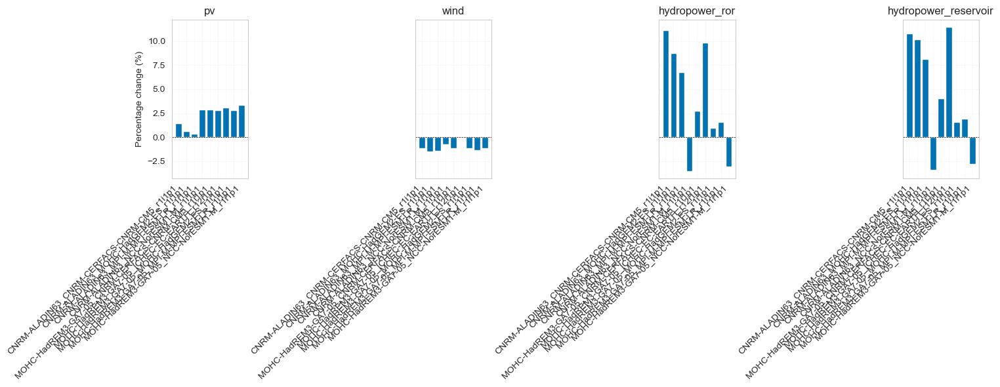

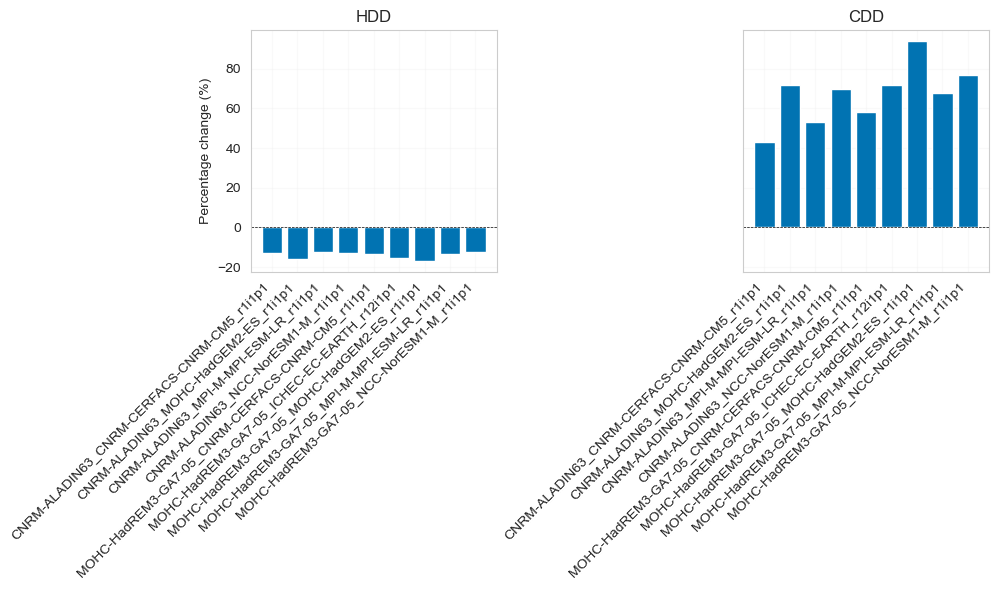

In [18]:
var = "hydropower"
# Create two separate figures: one for energy variables, one for demand variables
energy_vars = ["pv", "wind", "hydropower_ror", "hydropower_reservoir"]
demand_vars = ["HDD", "CDD"]

# Plot energy variables
fig1, axes1 = plt.subplots(1, len(energy_vars), figsize=(15, 6), sharey=True)
for i, var in enumerate(energy_vars):
    ax = axes1[i]

    # Compute percentage change for each model
    pct_change = []
    for model in valid_models:
        ref_val = mean_ref[var].sel(model=model).mean(dim=["lat", "lon"]).values
        mid_val = mean_mid_century[var].sel(model=model).mean(dim=["lat", "lon"]).values
        pct = (mid_val - ref_val) / ref_val * 100
        pct_change.append(pct)

    # Plot bar chart
    ax.bar(range(len(valid_models)), pct_change)
    ax.set_xticks(range(len(valid_models)))
    ax.set_xticklabels(
        ["_".join(m.split("_")[:-1]) for m in valid_models], rotation=45, ha="right"
    )
    ax.set_title(var)
    ax.set_ylabel("Percentage change (%)" if i == 0 else "")
    ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Plot demand variables
fig2, axes2 = plt.subplots(1, len(demand_vars), figsize=(10, 6), sharey=True)
for i, var in enumerate(demand_vars):
    ax = axes2[i]

    # Compute percentage change for each model
    pct_change = []
    for model in valid_models:
        ref_val = mean_ref[var].sel(model=model).mean(dim=["lat", "lon"]).values
        mid_val = mean_mid_century[var].sel(model=model).mean(dim=["lat", "lon"]).values
        pct = (mid_val - ref_val) / ref_val * 100
        pct_change.append(pct)

    # Plot bar chart
    ax.bar(range(len(valid_models)), pct_change)
    ax.set_xticks(range(len(valid_models)))
    ax.set_xticklabels(
        ["_".join(m.split("_")[:-1]) for m in valid_models], rotation=45, ha="right"
    )
    ax.set_title(var)
    ax.set_ylabel("Percentage change (%)" if i == 0 else "")
    ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

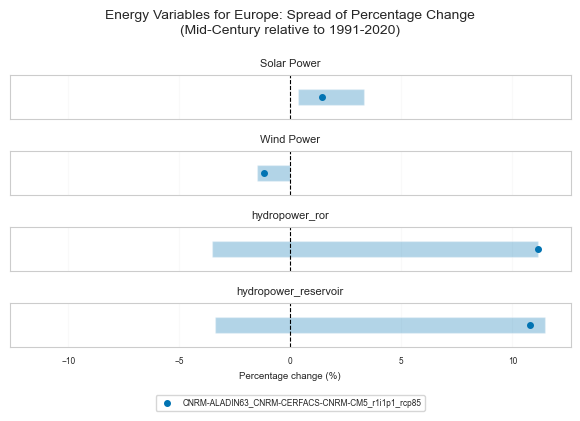

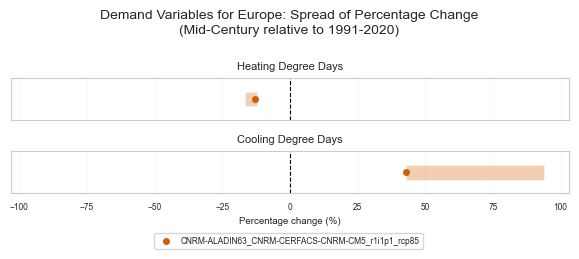

In [19]:
energy_vars = ["pv", "wind", "hydropower_ror", "hydropower_reservoir"]
demand_vars = ["HDD", "CDD"]
selected_model = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"

components_size_config = {
    "FONTSIZE_LEGEND": 6,
    "FONTSIZE_TICKS": 6,
    "FONTSIZE_LABELS": 7,
    "FONTSIZE_TITLE": 10,
    "MARKER_SIZE": 4,
    "BAR_HEIGHT": 0.35,
    "BBOX_TO_ANCHOR": (0.5, -0.05),
}
plot_percentage_change_spread(
    mean_ref,
    mean_mid_century,
    variables=energy_vars,
    valid_models=valid_models,
    selected_model=selected_model,
    color=BLUE,
    components_size_config=components_size_config,
    bar_alpha=0.3,
    figsize=("15cm", "10cm"),
    title="Energy Variables for Europe: Spread of Percentage Change\n(Mid-Century relative to 1991-2020)",
    path_savefig=path_figs
    / "energy"
    / "spread_percentage_change_renewables_europe.png",
)

plot_percentage_change_spread(
    mean_ref,
    mean_mid_century,
    variables=demand_vars,
    valid_models=valid_models,
    selected_model=selected_model,
    color=RED,
    components_size_config=components_size_config,
    bar_alpha=0.3,
    figsize=("15cm", "6cm"),
    title="Demand Variables for Europe: Spread of Percentage Change\n(Mid-Century relative to 1991-2020)",
    path_savefig=path_figs / "energy" / "spread_percentage_change_demand_europe.png",
)

## Visual inspection per model

In [20]:
visual_inspection = False

if visual_inspection:
    for model in mean_ref.model.values:
        fig, ax = plt.subplots(
            2,
            len(mean_ref.data_vars.keys()),
            figsize=(15, 10),
            subplot_kw={
                "projection": ccrs.Mercator(
                    central_longitude=10.0, min_latitude=30.0, max_latitude=75.0
                )
            },
        )
        for i, var in enumerate(mean_ref.data_vars.keys()):
            mean_ref.sel(model=model).data_vars[var].plot(
                ax=ax[0, i],
                transform=ccrs.PlateCarree(),
                vmax=mean_ref[var].quantile(0.99) if var in ["HDD", "CDD"] else None,
            )
            ax[0, i].set_title(var + " (Reference Period)")
        for i, var in enumerate(mean_mid_century.data_vars.keys()):
            mean_mid_century.sel(model=model).data_vars[var].plot(
                ax=ax[1, i],
                transform=ccrs.PlateCarree(),
                vmax=mean_mid_century[var].quantile(0.99)
                if var in ["HDD", "CDD"]
                else None,
            )
            ax[1, i].set_title(var + " (Mid-Century)")
        plt.suptitle(model)
        plt.tight_layout()
        plt.show()

## Poster figures

In [21]:
var_titles = {
    "pv": "Solar Power Potential",
    "wind": "Wind Power Potential",
    "hydropower_ror": "RoR Hydropower Potential",
    "HDD": "Heating Degree Days",
    "CDD": "Cooling Degree Days",
}
var_clabel = {
    "pv": "Generation (GWh)",
    "wind": "Generation (GWh)",
    "hydropower_ror": "Generation (GWh)",
    "HDD": "Degree-Days",
    "CDD": "Degree-Days",
}


component_sizes_ensemble_mean_europe_poster = {
    "FONTSIZE_LEGEND": 9,
    "FONTSIZE_TICKS": 11,
    "FONTSIZE_LABELS": 12,
    "FONTSIZE_TITLE": 12,
    "CBAR_SHRINK": 0.75,
    "CBAR_ASPECT": 15,
    "CBAR_PAD": 0.03,
}

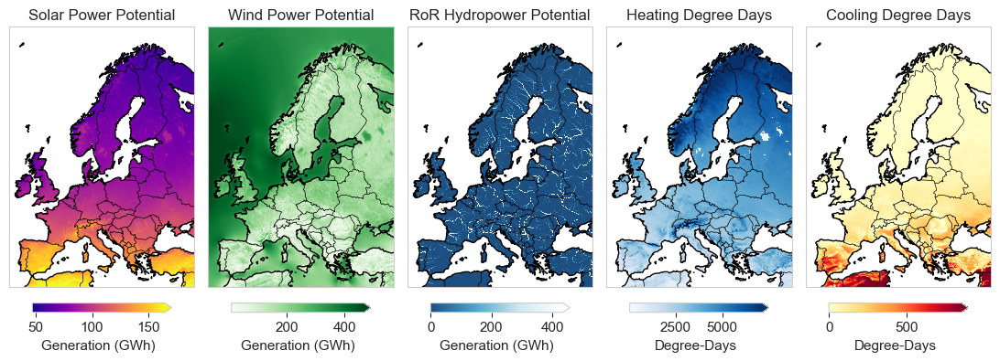

In [22]:
mean_ref_plot = mean_ref.copy()[["pv", "wind", "hydropower_ror", "HDD", "CDD"]]
# mean_ref_plot["hydropower_ror"] = np.log10(np.clip(mean_ref_plot["hydropower_ror"] * 365, 0.0001, None))
mean_ref_plot["hydropower_ror"] = mean_ref_plot["hydropower_ror"] * 365 * 24 * 1e-3
mean_ref_plot["pv"] = mean_ref_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_ref_plot["wind"] = mean_ref_plot["wind"] * 100 * 365 * 24 * 1e-3

plot_ensemble_mean(
    mean_ref_plot,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_europe_poster,
    # log_scale_vars=["hydropower_ror"],
    figsize=("28cm", "16cm"),
    country_border_width=0.5,
    title=None,
    path_savefig=path_figs / "speed2zero" / "poster" / "fig1.1.png",
)

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


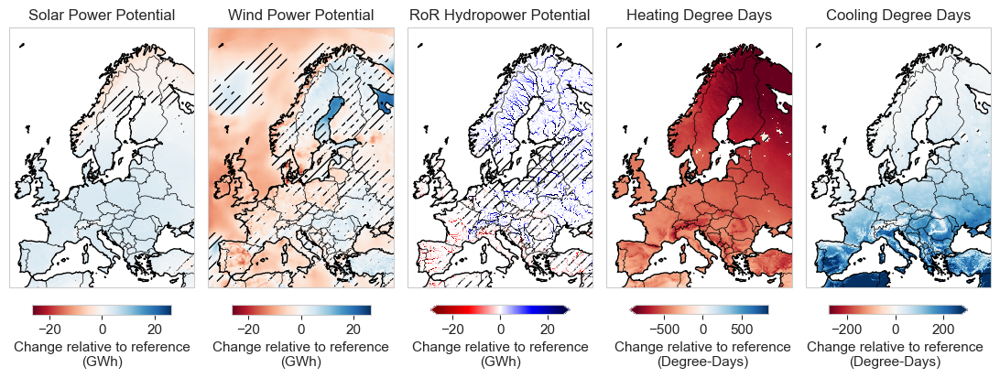

In [23]:
mean_ref_plot = mean_ref.copy()[["pv", "wind", "hydropower_ror", "HDD", "CDD"]]
mean_ref_plot["hydropower_ror"] = mean_ref_plot["hydropower_ror"] * 365 * 24 * 1e-3
mean_ref_plot["pv"] = mean_ref_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_ref_plot["wind"] = mean_ref_plot["wind"] * 100 * 365 * 24 * 1e-3

mean_mid_century_plot = mean_mid_century.copy()[
    ["pv", "wind", "hydropower_ror", "HDD", "CDD"]
]
mean_mid_century_plot["hydropower_ror"] = (
    mean_mid_century_plot["hydropower_ror"] * 365 * 24 * 1e-3
)
mean_mid_century_plot["pv"] = mean_mid_century_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_mid_century_plot["wind"] = mean_mid_century_plot["wind"] * 100 * 365 * 24 * 1e-3

var_clabel = {
    "pv": "Change relative to reference\n(GWh)",
    "wind": "Change relative to reference\n(GWh)",
    "hydropower_ror": "Change relative to reference\n(GWh)",
    "HDD": "Change relative to reference\n(Degree-Days)",
    "CDD": "Change relative to reference\n(Degree-Days)",
}

plot_ensemble_mean_change(
    mean_ref_plot,
    mean_mid_century_plot,
    absolute_change=True,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_europe_poster,
    figsize=("28cm", "17cm"),
    title=None,
    path_savefig=path_figs / "speed2zero" / "poster" / "fig1.2.png",
)

In [24]:
component_sizes_ensemble_mean_europe_poster_vertical = {
    "FONTSIZE_LEGEND": 9,
    "FONTSIZE_TICKS": 11.5,
    "FONTSIZE_LABELS": 12.5,
    "FONTSIZE_TITLE": 12,
    "CBAR_SHRINK": 0.40,
    "CBAR_ASPECT": 15,
    "CBAR_PAD": 0.03,
}

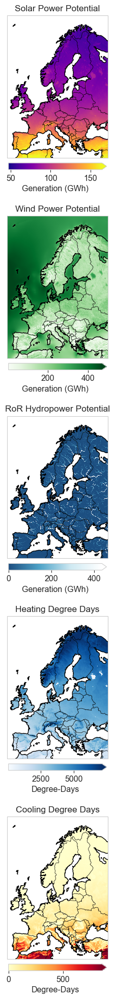

In [25]:
var_clabel = {
    "pv": "Generation (GWh)",
    "wind": "Generation (GWh)",
    "hydropower_ror": "Generation (GWh)",
    "HDD": "Degree-Days",
    "CDD": "Degree-Days",
}

mean_ref_plot = mean_ref.copy()[["pv", "wind", "hydropower_ror", "HDD", "CDD"]]
# mean_ref_plot["hydropower_ror"] = np.log10(np.clip(mean_ref_plot["hydropower_ror"] * 365, 0.0001, None))
mean_ref_plot["hydropower_ror"] = mean_ref_plot["hydropower_ror"] * 365 * 24 * 1e-3
mean_ref_plot["pv"] = mean_ref_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_ref_plot["wind"] = mean_ref_plot["wind"] * 100 * 365 * 24 * 1e-3

plot_ensemble_mean(
    mean_ref_plot,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_europe_poster_vertical,
    # log_scale_vars=["hydropower_ror"],
    figsize=("13cm", "50cm"),
    orientation="vertical",
    country_border_width=0.5,
    title=None,
    path_savefig=path_figs / "speed2zero" / "poster" / "fig1.1_vertical.png",
)

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


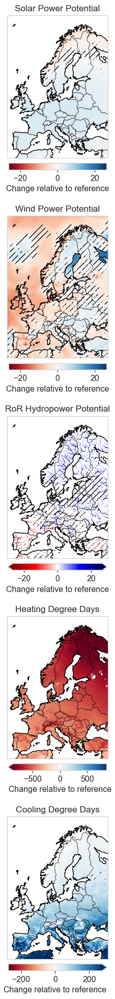

In [26]:
mean_ref_plot = mean_ref.copy()[["pv", "wind", "hydropower_ror", "HDD", "CDD"]]
mean_ref_plot["hydropower_ror"] = mean_ref_plot["hydropower_ror"] * 365 * 24 * 1e-3
mean_ref_plot["pv"] = mean_ref_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_ref_plot["wind"] = mean_ref_plot["wind"] * 100 * 365 * 24 * 1e-3

mean_mid_century_plot = mean_mid_century.copy()[
    ["pv", "wind", "hydropower_ror", "HDD", "CDD"]
]
mean_mid_century_plot["hydropower_ror"] = (
    mean_mid_century_plot["hydropower_ror"] * 365 * 24 * 1e-3
)
mean_mid_century_plot["pv"] = mean_mid_century_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_mid_century_plot["wind"] = mean_mid_century_plot["wind"] * 100 * 365 * 24 * 1e-3

var_clabel = {
    "pv": "Change relative to reference",
    "wind": "Change relative to reference",
    "hydropower_ror": "Change relative to reference",
    "HDD": "Change relative to reference",
    "CDD": "Change relative to reference",
}

plot_ensemble_mean_change(
    mean_ref_plot,
    mean_mid_century_plot,
    absolute_change=True,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_europe_poster_vertical,
    figsize=("13cm", "50cm"),
    orientation="vertical",
    title=None,
    path_savefig=path_figs / "speed2zero" / "poster" / "fig1.2_vertical.png",
)

## Ensemble mean

In [27]:
var_titles = {
    "pv": "Solar Power Potential",
    "wind": "Wind Power Potential",
    "hydropower_ror": "RoR Hydropower Potential",
    "hydropower_reservoir": "Reservoir Hydropower Inflows",
    "HDD": "Heating Degree Days",
    "CDD": "Cooling Degree Days",
}
var_clabel = {
    "pv": "Capacity Factor (-)",
    "wind": "Capacity Factor (-)",
    "hydropower_ror": "Generation (MWh)",
    "hydropower_reservoir": "Weekly Inflows (m³/s)",
    "HDD": "Degree-Days",
    "CDD": "Degree-Days",
}

component_sizes_ensemble_mean_europe = {
    "FONTSIZE_LEGEND": 18,
    "FONTSIZE_TICKS": 16,
    "FONTSIZE_LABELS": 19,
    "FONTSIZE_TITLE": 22,
    "CBAR_SHRINK": 0.75,
    "CBAR_ASPECT": 15,
    "CBAR_PAD": 0.03,
}

component_sizes_ensemble_mean_europe_poster = {
    "FONTSIZE_LEGEND": 9,
    "FONTSIZE_TICKS": 11,
    "FONTSIZE_LABELS": 12,
    "FONTSIZE_TITLE": 12,
    "CBAR_SHRINK": 0.75,
    "CBAR_ASPECT": 15,
    "CBAR_PAD": 0.03,
}

var_clabel = {
    "pv": "Generation (GWh)",
    "wind": "Generation (GWh)",
    "hydropower_ror": "Generation (GWh)",
    "HDD": "Degree-Days",
    "CDD": "Degree-Days",
}

mean_ref_plot = mean_ref.copy()[["pv", "wind", "hydropower_ror", "HDD", "CDD"]]
# mean_ref_plot["hydropower_ror"] = np.log10(np.clip(mean_ref_plot["hydropower_ror"] * 365, 0.0001, None))
mean_ref_plot["hydropower_ror"] = mean_ref_plot["hydropower_ror"] * 365 * 24 * 1e-3
mean_ref_plot["pv"] = mean_ref_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_ref_plot["wind"] = mean_ref_plot["wind"] * 100 * 365 * 24 * 1e-3

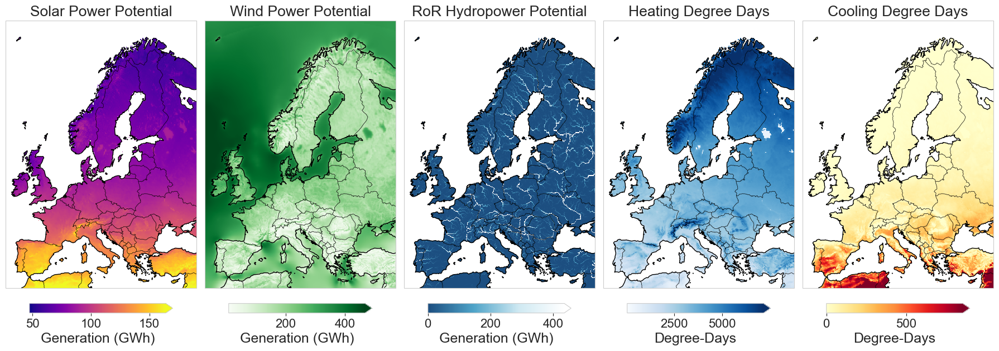

In [28]:
plot_ensemble_mean(
    mean_ref_plot,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_europe,
    # log_scale_vars=["hydropower_ror", "hydropower_reservoir"],
    figsize=(18, 9.5),
    country_border_width=0.5,
    title=None,
    # simplify_colorbar=True,
    path_savefig=path_figs / "energy" / "mean_ref_europe.png",
)

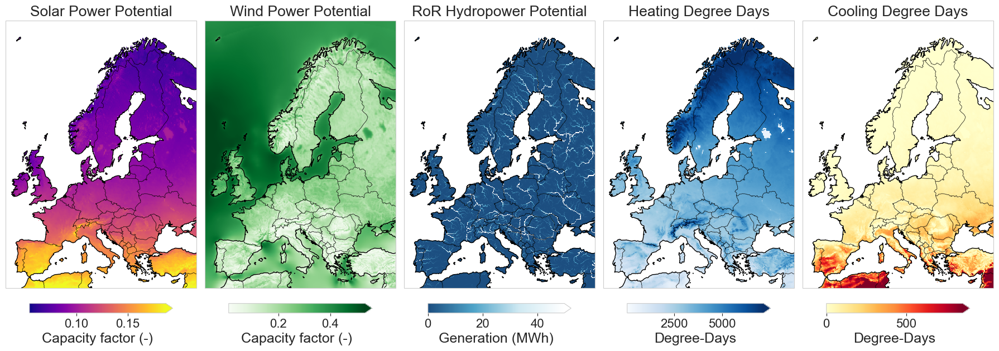

In [29]:
var_clabel = {
    "pv": "Capacity factor (-)",
    "wind": "Capacity factor (-)",
    "hydropower_ror": "Generation (MWh)",
    "HDD": "Degree-Days",
    "CDD": "Degree-Days",
}

plot_ensemble_mean(
    mean_ref[["pv", "wind", "hydropower_ror", "HDD", "CDD"]],
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_europe,
    # log_scale_vars=["hydropower_ror", "hydropower_reservoir"],
    figsize=(18, 9.5),
    country_border_width=0.5,
    title=None,
    # simplify_colorbar=True,
    path_savefig=path_figs / "energy" / "mean_ref_capacity_factors_europe.png",
)

### SPEED2ZERO Poster Figures

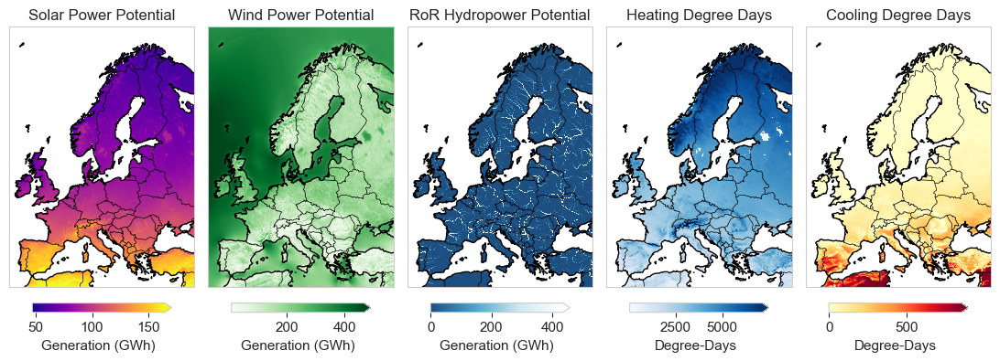

In [30]:
var_clabel = {
    "pv": "Generation (GWh)",
    "wind": "Generation (GWh)",
    "hydropower_ror": "Generation (GWh)",
    "HDD": "Degree-Days",
    "CDD": "Degree-Days",
}

mean_ref_plot = mean_ref.copy()[["pv", "wind", "hydropower_ror", "HDD", "CDD"]]
# mean_ref_plot["hydropower_ror"] = np.log10(np.clip(mean_ref_plot["hydropower_ror"] * 365, 0.0001, None))
mean_ref_plot["hydropower_ror"] = mean_ref_plot["hydropower_ror"] * 365 * 24 * 1e-3
mean_ref_plot["pv"] = mean_ref_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_ref_plot["wind"] = mean_ref_plot["wind"] * 100 * 365 * 24 * 1e-3

plot_ensemble_mean(
    mean_ref_plot,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_europe_poster,
    # log_scale_vars=["hydropower_ror"],
    figsize=("28cm", "16cm"),
    country_border_width=0.5,
    title=None,
    path_savefig=path_figs / "speed2zero" / "poster" / "fig1.png",
)

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


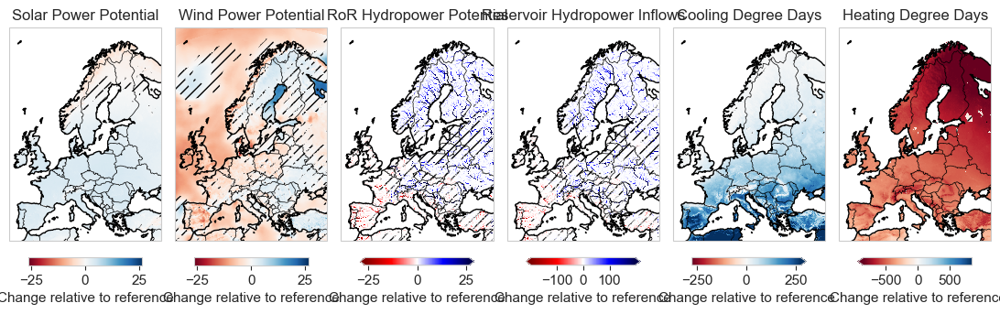

In [31]:
mean_ref_plot = mean_ref.copy()
mean_ref_plot["hydropower_ror"] = mean_ref_plot["hydropower_ror"] * 365 * 24 * 1e-3
mean_ref_plot["pv"] = mean_ref_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_ref_plot["wind"] = mean_ref_plot["wind"] * 100 * 365 * 24 * 1e-3

mean_mid_century_plot = mean_mid_century.copy()
mean_mid_century_plot["hydropower_ror"] = (
    mean_mid_century_plot["hydropower_ror"] * 365 * 24 * 1e-3
)
mean_mid_century_plot["pv"] = mean_mid_century_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_mid_century_plot["wind"] = mean_mid_century_plot["wind"] * 100 * 365 * 24 * 1e-3

var_clabel = {
    "pv": "Change relative to reference",
    "wind": "Change relative to reference",
    "hydropower_ror": "Change relative to reference",
    "HDD": "Change relative to reference",
    "CDD": "Change relative to reference",
}
# var_clabel = None

plot_ensemble_mean_change(
    mean_ref_plot,
    mean_mid_century_plot,
    absolute_change=True,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_europe_poster,
    figsize=("28cm", "16cm"),
    title=None,
    path_savefig=path_figs / "speed2zero" / "poster" / "fig1.3.png",
)
# path_savefig=path_figs / "energy" / "mean_change_mid_century.png")

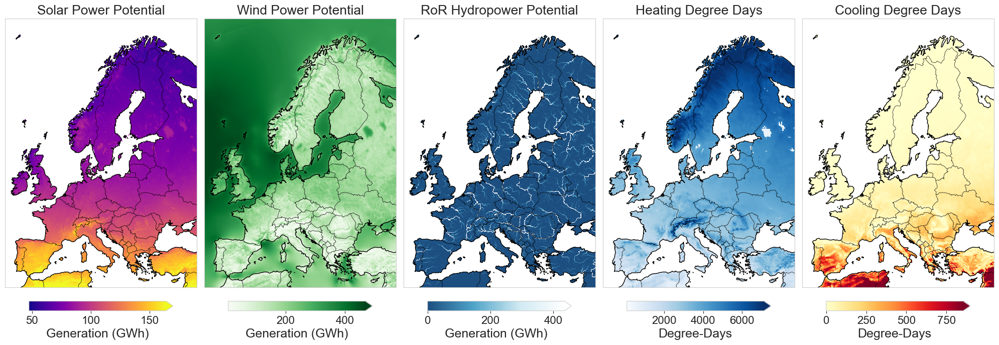

In [32]:
var_clabel = {
    "pv": "Generation (GWh)",
    "wind": "Generation (GWh)",
    "hydropower_ror": "Generation (GWh)",
    "HDD": "Degree-Days",
    "CDD": "Degree-Days",
}

mean_ref_plot = mean_ref.copy()[["pv", "wind", "hydropower_ror", "HDD", "CDD"]]
# mean_ref_plot["hydropower_ror"] = np.log10(np.clip(mean_ref_plot["hydropower_ror"] * 365, 0.0001, None))
mean_ref_plot["hydropower_ror"] = mean_ref_plot["hydropower_ror"] * 365 * 24 * 1e-3
mean_ref_plot["pv"] = mean_ref_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_ref_plot["wind"] = mean_ref_plot["wind"] * 100 * 365 * 24 * 1e-3

plot_ensemble_mean(
    mean_ref_plot,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_europe,
    # log_scale_vars=["hydropower_ror"],
    figsize=(20, 9.5),
    country_border_width=0.5,
    title=None,
    path_savefig=path_figs / "speed2zero" / "poster" / "fig1.png",
)

## Ensemble mean change

In [33]:
mean_mid_century_plot = mean_mid_century.copy()
mean_mid_century_plot["hydropower_ror"] = (
    mean_mid_century_plot["hydropower_ror"] * 365 * 24 * 1e-3
)
mean_mid_century_plot["pv"] = mean_mid_century_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_mid_century_plot["wind"] = mean_mid_century_plot["wind"] * 100 * 365 * 24 * 1e-3

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


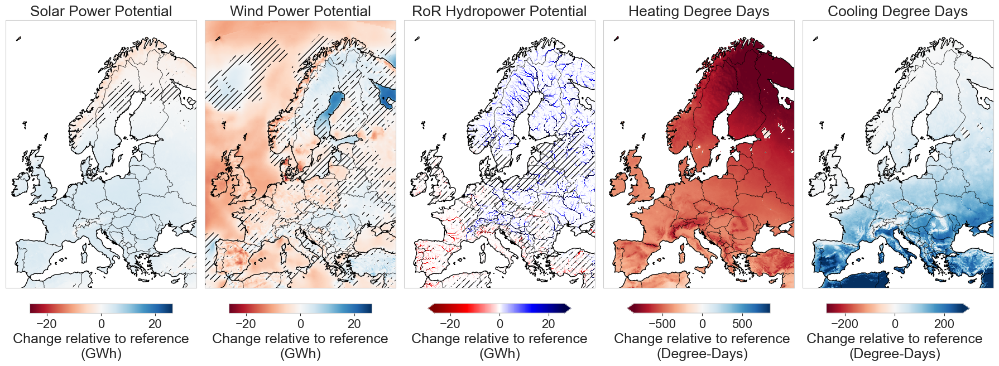

In [34]:
var_clabel = {
    "pv": "Change relative to reference\n(GWh)",
    "wind": "Change relative to reference\n(GWh)",
    "hydropower_ror": "Change relative to reference\n(GWh)",
    "HDD": "Change relative to reference\n(Degree-Days)",
    "CDD": "Change relative to reference\n(Degree-Days)",
}

plot_ensemble_mean_change(
    mean_ref_plot,
    mean_mid_century_plot,
    absolute_change=True,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_europe,
    figsize=(18, 9.5),
    title=None,
    path_savefig=path_figs
    / "energy"
    / "mean_absolute_change_mid_century_europe.png",
)
# path_savefig=path_figs / "energy" / "mean_percentage_change_mid_century.png")

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


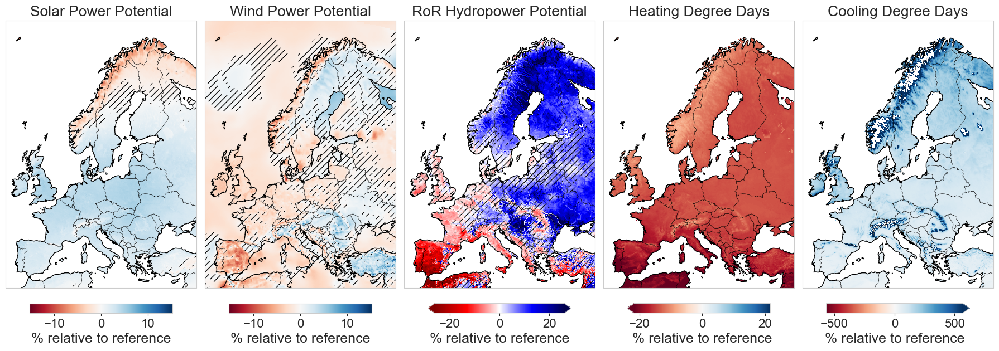

In [35]:
plot_ensemble_mean_change(
    mean_ref_plot,
    mean_mid_century_plot,
    var_titles=var_titles,
    components_size_config=component_sizes_ensemble_mean_europe,
    figsize=(18, 9.5),
    title=None,
    path_savefig=path_figs
    / "energy"
    / "mean_percentage_change_mid_century_europe.png",
)

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


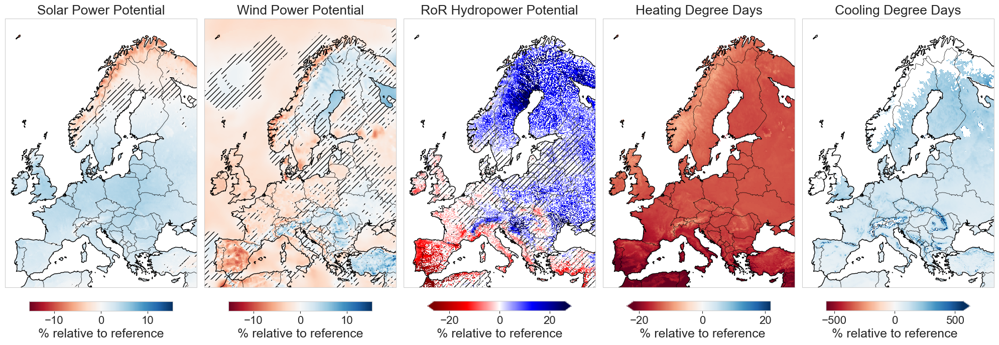

In [36]:
significance_thresholds = {
    "pv": 0,
    "wind": 0,
    "hydropower_ror": 0.1,
    "hydropower_reservoir": 0.1,
    "HDD": 10,
    "CDD": 10,
}
plot_ensemble_mean_change(
    mean_ref_plot,
    mean_mid_century_plot,
    var_titles=var_titles,
    components_size_config=component_sizes_ensemble_mean_europe,
    figsize=(20, 9.5),
    title=None,
    mask_insignificant=True,
    significance_threshold=significance_thresholds,
    path_savefig=path_figs
    / "energy"
    / "mean_percentage_change_mid_century_masked_europe.png",
)
# path_savefig=path_figs / "energy" / "mean_percentage_change_mid_century.png")

### SPEED2ZERO poster figures

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


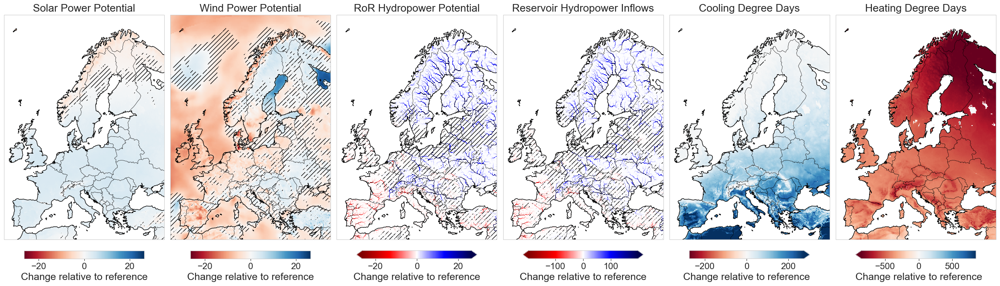

In [ ]:
mean_ref_plot = mean_ref.copy()
mean_ref_plot["hydropower_ror"] = mean_ref_plot["hydropower_ror"] * 365 * 24 * 1e-3
mean_ref_plot["pv"] = mean_ref_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_ref_plot["wind"] = mean_ref_plot["wind"] * 100 * 365 * 24 * 1e-3

mean_mid_century_plot = mean_mid_century.copy()
mean_mid_century_plot["hydropower_ror"] = (
    mean_mid_century_plot["hydropower_ror"] * 365 * 24 * 1e-3
)
mean_mid_century_plot["pv"] = mean_mid_century_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_mid_century_plot["wind"] = mean_mid_century_plot["wind"] * 100 * 365 * 24 * 1e-3

var_clabel = {
    "pv": "Change relative to reference",
    "wind": "Change relative to reference",
    "hydropower_ror": "Change relative to reference",
    "hydropower_reservoir": "Change relative to reference",
    "HDD": "Change relative to reference",
    "CDD": "Change relative to reference",
}
# var_clabel = None

plot_ensemble_mean_change(
    mean_ref_plot,
    mean_mid_century_plot,
    absolute_change=True,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_europe,
    figsize=(25, 9.5),
    title=None,
    path_savefig=path_figs
    / "speed2zero"
    / "mean_absolute_change_mid_century_europe.png",
)
# path_savefig=path_figs / "energy" / "mean_change_mid_century.png")

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


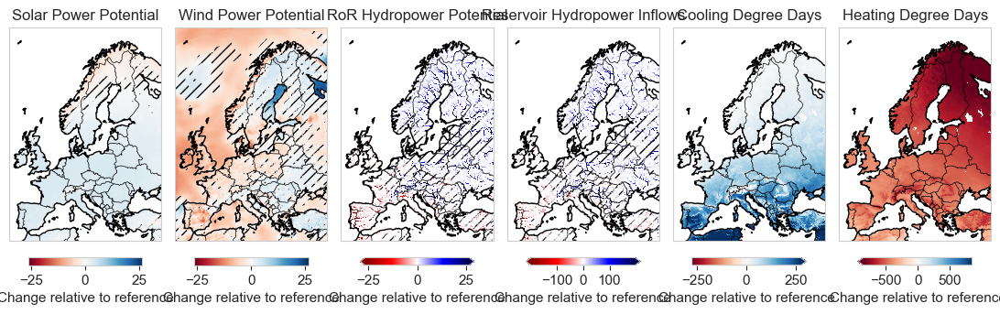

In [35]:
mean_ref_plot = mean_ref.copy()
mean_ref_plot["hydropower_ror"] = mean_ref_plot["hydropower_ror"] * 365 * 24 * 1e-3
mean_ref_plot["pv"] = mean_ref_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_ref_plot["wind"] = mean_ref_plot["wind"] * 100 * 365 * 24 * 1e-3

mean_mid_century_plot = mean_mid_century.copy()
mean_mid_century_plot["hydropower_ror"] = (
    mean_mid_century_plot["hydropower_ror"] * 365 * 24 * 1e-3
)
mean_mid_century_plot["pv"] = mean_mid_century_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_mid_century_plot["wind"] = mean_mid_century_plot["wind"] * 100 * 365 * 24 * 1e-3

var_clabel = {
    "pv": "Change relative to reference",
    "wind": "Change relative to reference",
    "hydropower_ror": "Change relative to reference",
    "HDD": "Change relative to reference",
    "CDD": "Change relative to reference",
}
# var_clabel = None

plot_ensemble_mean_change(
    mean_ref_plot,
    mean_mid_century_plot,
    absolute_change=True,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_europe_poster,
    figsize=("28cm", "16cm"),
    title=None,
    path_savefig=path_figs / "speed2zero" / "poster" / "fig1.3.png",
)
# path_savefig=path_figs / "energy" / "mean_change_mid_century.png")

## Renewables as function of electricity demand per grid cell

In [59]:
components_size_renewables_demand = {
    "FONTSIZE_LEGEND": 10,
    "FONTSIZE_TICKS": 10,
    "FONTSIZE_LABELS": 13,
    "FONTSIZE_TITLE": 15,
}

In [60]:
(path_figs / "energy" / "supply_demand").mkdir(parents=True, exist_ok=True)

In [61]:
da_worldpop_coarse = process_population_data(
    sel_extent(
        rxr.open_rasterio(
            Path(paths["path_data_processed"]) / "pop" / "ppp_2020_1km_Aggregated.tif"
        ).rename({"x": "lon", "y": "lat"}),
        extent=extent_pop,
    ),
    sel_extent(mean_ref.drop_vars(["band", "spatial_ref"]), extent=extent),
    coarsen=True,
)

countries = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
mask_countries_worldpop = countries.mask(da_worldpop_coarse, flag="names")
da_worldpop_coarse = normalize_population_data(
    da_worldpop_coarse, mask_countries_worldpop
).where(da_worldpop_coarse > 0, np.nan)

In [62]:
df_electricity_stats = pd.read_csv(
    Path(paths["path_data_processed"]).parent
    / "datasets"
    / "energy"
    / "electricity_stats"
    / "ember_energy_europe_yearly_full_release_long_format.csv"
)
df_demand = df_electricity_stats[df_electricity_stats["Subcategory"] == "Demand"]
df_demand_2025 = df_demand[df_demand["Year"] == 2025].copy().reset_index(drop=True)

In [63]:
demand_by_country = (
    df_demand_2025.groupby("Area")["Value"].sum() * 1e6
)  # Convert from TWh to MWh

# Align country names with regionmask naming conventions
demand_by_country = demand_by_country.rename(
    index={"Bosnia Herzegovina": "Bosnia and Herz.", "Türkiye": "Turkey"}
)

# Build a flag-value → demand mapping using the regionmask regions object.
# mask_countries_worldpop contains integer flag values; countries.regions maps them to names.
flag_to_demand = {
    flag: demand_by_country.get(region.name, np.nan)
    for flag, region in countries.regions.items()
}

### Per grid cell

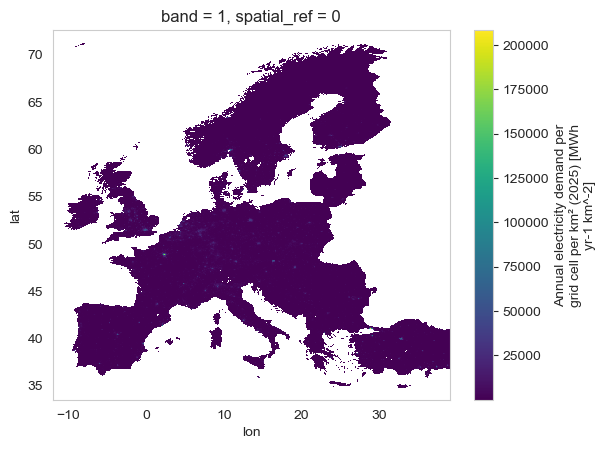

In [64]:
# Distribute country-level demand (2025) to grid cells using normalized population weights.
# da_worldpop_coarse is normalized so that sum of weights within each country = 1,
# so: da_demand_gridded[cell] = demand[country] * pop_weight[cell]
# and summing over a country's grid cells recovers the country's total demand.


# Build a DataArray that assigns each grid cell its country's total demand
da_country_demand = xr.full_like(
    mask_countries_worldpop, fill_value=np.nan, dtype=float
)
for flag_value, demand in flag_to_demand.items():
    if not np.isnan(demand):
        da_country_demand = xr.where(
            mask_countries_worldpop == flag_value, float(demand), da_country_demand
        )

# Spatially disaggregate: demand per grid cell proportional to population weight
da_demand_gridded = (
    da_worldpop_coarse * da_country_demand / (cell_area_km2(da_worldpop_coarse))
)
da_demand_gridded.attrs["long_name"] = (
    "Annual electricity demand per grid cell per km² (2025)"
)
# da_demand_gridded.attrs["units"] = df_demand_2025["Unit"].iloc[0] if "Unit" in df_demand_2025.columns else "TWh"
da_demand_gridded.attrs["units"] = (
    "MWh yr-1 km^-2"  # Since we multiplied by 1e6 above to convert from TWh to MWh
)

da_demand_gridded.plot()

/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/cartopy/mpl/geoaxes.py:528: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from current font.
  super()._update_title_position(renderer)
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/cartopy/mpl/geoaxes.py:528: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from current font.
  super()._update_title_position(renderer)
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/cartopy/mpl/geoaxes.py:525: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from current font.
  return super().draw(renderer=renderer, **kwargs)


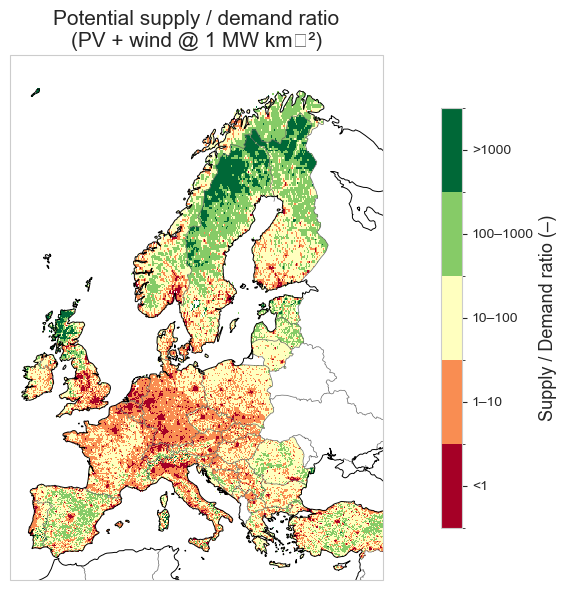

In [65]:

_fs = components_size_renewables_demand

power_density_MW_per_km2 = 1
ratio = (
    (mean_ref["pv"].mean("model") + mean_ref["wind"].mean("model"))
    * 8760
    * power_density_MW_per_km2
) / da_demand_gridded

# Binned colorbar: <1, 1-10, 10-100, 100-1000, >1000
bounds = [0, 1, 10, 100, 1000, ratio.max().item()]
labels = ["<1", "1–10", "10–100", "100–1000", ">1000"]
n_bins = len(bounds) - 1
cmap = plt.get_cmap("RdYlGn", n_bins)
norm = mcolors.BoundaryNorm(bounds, ncolors=n_bins, clip=True)

fig, ax = plt.subplots(
    figsize=(12, 6),
    subplot_kw={"projection": ccrs.Mercator()},
)

img = ratio.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    add_colorbar=False,
)

cbar = fig.colorbar(
    img,
    ax=ax,
    orientation="vertical",
    ticks=[(bounds[i] + bounds[i + 1]) / 2 for i in range(n_bins)],
    shrink=0.8,
)
cbar.ax.set_yticklabels(labels, fontsize=_fs["FONTSIZE_TICKS"])
cbar.set_label("Supply / Demand ratio (–)", fontsize=_fs["FONTSIZE_LABELS"])

ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="0.4")
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.set_title(
    f"Potential supply / demand ratio\n(PV + wind @ {power_density_MW_per_km2} MW km⁻²)",
    fontsize=_fs["FONTSIZE_TITLE"],
)
plt.tight_layout()
plt.show()


In [66]:
ratio.min().values, ratio.max().values

(array(0.01204534), array(14013160.05167325))

### Aggregated

#### Without land eligbility

In [67]:
# ── National-scale supply / demand ratio ──────────────────────────────────────
# Step 1: potential supply per grid cell [MWh / cell]
#   capacity_factor [–] × 8760 h/yr × power_density [MW/km²] × cell_area [km²]
#   = MWh / yr per cell
# power_density_MW_per_km2 = 1
power_density_MW_per_km2_pv = pv_power_density(
    ROOFTOP_PV_CONFIGURATION, built_up_fraction=0.3
)
print("Power density MW per km² (PV):", power_density_MW_per_km2_pv)
power_density_MW_per_km2_wind = wind_power_density(
    EUROPE_TURBINES[0], hub_height_m=EUROPE_HUB_HEIGHTS[EUROPE_TURBINES[0]]
)["power_density_MW_km2"]

cell_area = cell_area_km2(da_worldpop_coarse)
supply_gridded = (
    (
        mean_ref["pv"].mean("model") * power_density_MW_per_km2_pv
        + mean_ref["wind"].mean("model") * power_density_MW_per_km2_wind
    )
    * 8760
    * cell_area
)  # MWh / yr per cell

# Step 2: aggregate to national totals [MWh / yr]
national_supply = {}
for region in countries.regions.values():
    mask = mask_countries_worldpop == region.number
    country_supply = float(supply_gridded.where(mask).sum(skipna=True).values)
    if country_supply > 0:
        national_supply[region.name] = country_supply

ds_national = pd.DataFrame(
    {
        "supply_MWh": pd.Series(national_supply),
        "demand_MWh": demand_by_country,
    }
).dropna()

ds_national["ratio"] = ds_national["supply_MWh"] / ds_national["demand_MWh"]
ds_national = ds_national.sort_values("ratio")
ds_national

Power density MW per km² (PV): 25.411764705882355

Wind turbine: E-126/7580  |  hub height: 127 m
  Rotor diameter   : 127.0 m
  Rated power      : 7.58 MW
  Layout           : 4.0D × 8.0D
  Area / turbine   : 0.5161 km²
  Power density    : 14.69 MW/km²

  Sensitivity to spacing (MW/km²):
    3.0D×7.0D  :   22.4
    3.0D×8.0D  :   19.6
    3.0D×9.0D  :   17.4
    4.0D×7.0D  :   16.8
    4.0D×8.0D  :   14.7 ← selected
    4.0D×9.0D  :   13.1
    5.0D×7.0D  :   13.4
    5.0D×8.0D  :   11.8
    5.0D×9.0D  :   10.4


,supply_MWh,demand_MWh,ratio
Malta,3.283091e+07,3230000.0,10.164367
Luxembourg,1.174316e+08,6700000.0,17.527099
Netherlands,2.182642e+09,121110000.0,18.021982
Belgium,1.682001e+09,86560000.0,19.431619
Switzerland,1.840536e+09,65120000.0,28.263754
Germany,1.742713e+10,520270000.0,33.496324
United Kingdom,1.422153e+10,321850000.0,44.186814
Italy,1.377182e+10,311600000.0,44.197099
Cyprus,2.615265e+08,5910000.0,44.251530
Austria,3.624681e+09,75840000.0,47.793784


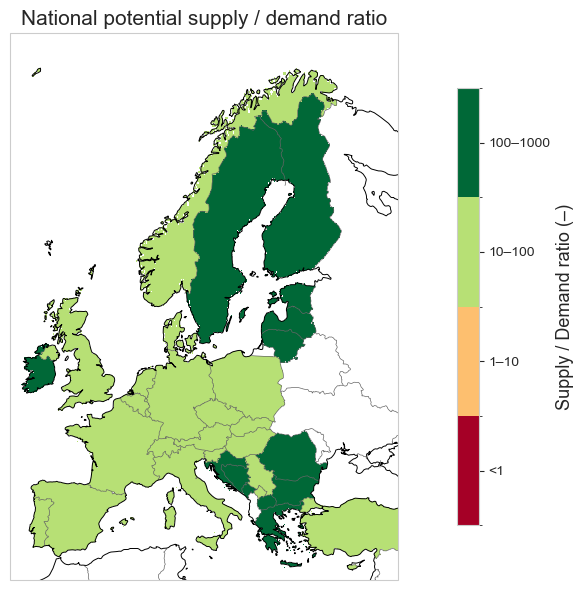

In [68]:

_fs = components_size_renewables_demand

# ── Plot national supply / demand ratio (choropleth map) ──────────────────────
bounds_nat = [0, 1, 10, 100, 1000]
if ds_national["ratio"].max() > bounds_nat[-1]:
    bounds_nat.append(ds_national["ratio"].max() * 1.1)
labels_nat = ["<1", "1–10", "10–100", "100–1000"]
if len(bounds_nat) > len(labels_nat) + 1:
    labels_nat.append(f">{bounds_nat[-2]:.0f}")
n_bins_nat = len(bounds_nat) - 1
cmap_nat = plt.get_cmap("RdYlGn", n_bins_nat)
norm_nat = mcolors.BoundaryNorm(bounds_nat, ncolors=n_bins_nat, clip=True)

# Build a DataArray on the mask grid: each cell gets the national ratio value
da_ratio_national = xr.full_like(
    mask_countries_worldpop, fill_value=np.nan, dtype=float
)
for region in countries.regions.values():
    if region.name in ds_national.index:
        da_ratio_national = xr.where(
            mask_countries_worldpop == region.number,
            ds_national.loc[region.name, "ratio"],
            da_ratio_national,
        )

fig, ax = plt.subplots(
    figsize=(12, 6),
    subplot_kw={"projection": ccrs.Mercator()},
)

img = da_ratio_national.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=cmap_nat,
    norm=norm_nat,
    add_colorbar=False,
)

cbar = fig.colorbar(
    img,
    ax=ax,
    orientation="vertical",
    ticks=[(bounds_nat[i] + bounds_nat[i + 1]) / 2 for i in range(n_bins_nat)],
    shrink=0.8,
)
cbar.ax.set_yticklabels(labels_nat, fontsize=_fs["FONTSIZE_TICKS"])
cbar.set_label("Supply / Demand ratio (–)", fontsize=_fs["FONTSIZE_LABELS"])

ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="0.4")
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.set_title("National potential supply / demand ratio", fontsize=_fs["FONTSIZE_TITLE"])
plt.tight_layout()
plt.show()


#### With land eligibility

In [69]:
clc_path = (
    Path(paths["path_data_processed"]).parent
    / "datasets"
    / "land_cover"
    / "corine_2018"
    / "DATA"
    / "U2018_CLC2018_V2020_20u1.tif"
)

eligibility_clc = sel_extent(
    xr.open_dataset(
        path_data_processed / "maps" / "land_eligibility" / "land_eligibility_with_wdpa.nc"
    ).rename({"x": "lon", "y": "lat"}),
    extent=extent,
)

pd_pv = apply_land_mask(pv_power_density(
    pv_config=ROOFTOP_PV_CONFIGURATION,
    built_up_fraction=eligibility_clc["built_up_fraction"],
    eligible_pv_openfield=eligibility_clc["eligible_fraction_pv_openfield"],
))

wind_result = wind_power_density("E-126/7580", hub_height_m=EUROPE_HUB_HEIGHTS["E-126/7580"])
pd_wind = wind_result["power_density_MW_km2"]


Wind turbine: E-126/7580  |  hub height: 127 m
  Rotor diameter   : 127.0 m
  Rated power      : 7.58 MW
  Layout           : 4.0D × 8.0D
  Area / turbine   : 0.5161 km²
  Power density    : 14.69 MW/km²

  Sensitivity to spacing (MW/km²):
    3.0D×7.0D  :   22.4
    3.0D×8.0D  :   19.6
    3.0D×9.0D  :   17.4
    4.0D×7.0D  :   16.8
    4.0D×8.0D  :   14.7 ← selected
    4.0D×9.0D  :   13.1
    5.0D×7.0D  :   13.4
    5.0D×8.0D  :   11.8
    5.0D×9.0D  :   10.4


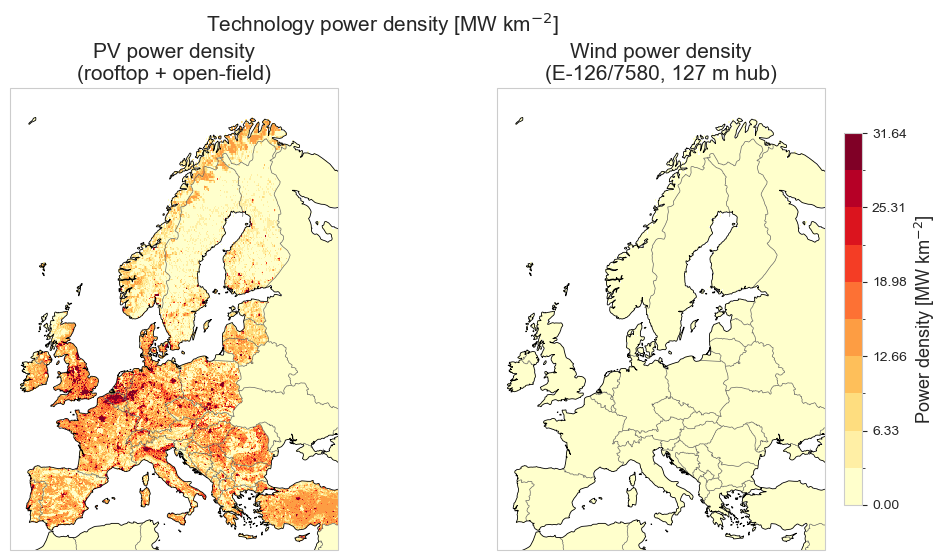

In [70]:

_fs = components_size_renewables_demand

# ── Power density: rooftop + open-field PV  |  onshore wind ──────────────────
# Both quantities are in MW km⁻² → shared colorbar allows direct comparison.
n_bins_pd = 10

fraction_wind = 0.2
pv_map   = sel_extent(apply_land_mask(pd_pv), extent=extent)
wind_map = sel_extent(apply_land_mask(eligibility_clc["eligible_fraction_wind"] * fraction_wind * pd_wind), extent=extent)

vmax_shared = max(float(pv_map.quantile(0.99)), float(wind_map.max()))
bounds_shared = np.linspace(0, vmax_shared, n_bins_pd + 1)
cmap_shared   = plt.get_cmap("YlOrRd", n_bins_pd)
norm_shared   = mcolors.BoundaryNorm(bounds_shared, ncolors=n_bins_pd)

proj = ccrs.Mercator()
fig, (ax_pv, ax_wind) = plt.subplots(
    1, 2,
    figsize=(12, 6),
    subplot_kw={"projection": proj},
)

# ── PV ──────────────────────────────────────────────────────────────────────
img_pv = pv_map.plot(
    ax=ax_pv,
    transform=ccrs.PlateCarree(),
    cmap=cmap_shared,
    norm=norm_shared,
    add_colorbar=False,
)
ax_pv.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="0.4")
ax_pv.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax_pv.set_title("PV power density\n(rooftop + open-field)", fontsize=_fs["FONTSIZE_TITLE"])

# ── Wind ─────────────────────────────────────────────────────────────────────
img_wind = wind_map.plot(
    ax=ax_wind,
    transform=ccrs.PlateCarree(),
    cmap=cmap_shared,
    norm=norm_shared,
    add_colorbar=False,
)
ax_wind.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="0.4")
ax_wind.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax_wind.set_title(
    f"Wind power density\n({wind_result['turbine_name']}, {wind_result['hub_height_m']} m hub)",
    fontsize=_fs["FONTSIZE_TITLE"],
)

# ── Shared colorbar ───────────────────────────────────────────────────────────
cbar = fig.colorbar(
    img_pv,
    ax=[ax_pv, ax_wind],
    orientation="vertical",
    fraction=0.02,
    pad=0.02,
    label=r"Power density [MW km$^{-2}$]",
)
cbar.ax.tick_params(labelsize=_fs["FONTSIZE_TICKS"])
cbar.ax.yaxis.label.set_size(_fs["FONTSIZE_LABELS"])

plt.suptitle(r"Technology power density [MW km$^{-2}$]", y=1.01, fontsize=_fs["FONTSIZE_TITLE"])
plt.show()


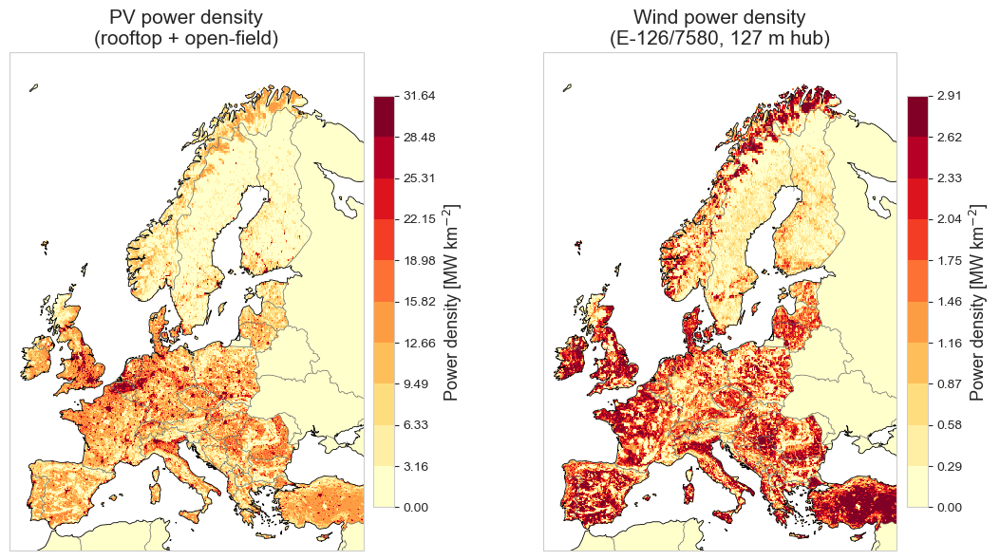

In [86]:

_fs = components_size_renewables_demand

# ── Power density: separate colorbars (each scaled to its own range) ──────────
n_bins_pd = 10

panels = {
    "PV power density\n(rooftop + open-field)": pv_map,
    f"Wind power density\n({wind_result['turbine_name']}, {wind_result['hub_height_m']} m hub)": wind_map,
}

proj = ccrs.Mercator()
fig, axs = plt.subplots(
    1, 2,
    figsize=(12, 6),
    subplot_kw={"projection": proj},
)

for ax, (title, da) in zip(axs, panels.items()):
    vmax   = float(da.quantile(0.99))
    bounds = np.linspace(0, vmax, n_bins_pd + 1)
    cmap   = plt.get_cmap("YlOrRd", n_bins_pd)
    norm   = mcolors.BoundaryNorm(bounds, ncolors=n_bins_pd)

    img = da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        norm=norm,
        add_colorbar=False,
    )
    ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="0.4")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.set_title(title, fontsize=_fs["FONTSIZE_TITLE"])

    cbar = fig.colorbar(
        img,
        ax=ax,
        orientation="vertical",
        fraction=0.04,
        pad=0.02,
        label=r"Power density [MW km$^{-2}$]",
    )
    cbar.set_ticks(bounds)
    cbar.set_ticklabels([f"{v:.2f}" for v in bounds], fontsize=_fs["FONTSIZE_TICKS"])
    cbar.ax.yaxis.label.set_size(_fs["FONTSIZE_LABELS"])

plt.tight_layout()
plt.show()


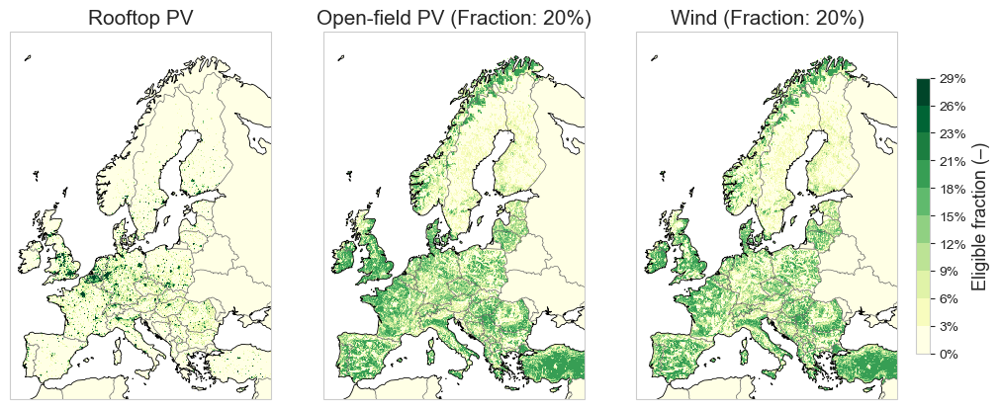

In [72]:

_fs = components_size_renewables_demand

# ── Land eligibility fractions: rooftop PV | open-field PV | wind ────────────
# fraction_wind: planning constraint — only this share of wind-eligible land
# is assumed to be actually developed (same value used in generation cells).
fraction_wind_elig = 0.2

maps_el = {
    "Rooftop PV": apply_land_mask(eligibility_clc["eligible_fraction_pv_rooftop"]),
    "Open-field PV (Fraction: 20%)": apply_land_mask(eligibility_clc["eligible_fraction_pv_openfield"]),
    f"Wind (Fraction: {fraction_wind_elig:.0%})": apply_land_mask(
        eligibility_clc["eligible_fraction_wind"] * fraction_wind_elig
    ),
}

# Derive a shared vmax from the 99th percentile across all three layers
vmax_el   = max(float(da.quantile(0.99)) for da in maps_el.values())
n_bins_el = 10
bounds_el = np.linspace(0, vmax_el, n_bins_el + 1)
cmap_el   = plt.get_cmap("YlGn", n_bins_el)
norm_el   = mcolors.BoundaryNorm(bounds_el, ncolors=n_bins_el)

proj = ccrs.Mercator()
fig, axs = plt.subplots(
    1, 3,
    figsize=(12, 6),
    subplot_kw={"projection": proj},
)

for ax, (title, da) in zip(axs, maps_el.items()):
    img = da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=cmap_el,
        norm=norm_el,
        add_colorbar=False,
    )
    ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="0.4")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.set_title(title, fontsize=_fs["FONTSIZE_TITLE"])

cbar = fig.colorbar(
    img,
    ax=axs,
    orientation="vertical",
    fraction=0.015,
    pad=0.02,
    label="Eligible fraction (–)",
)
cbar.set_ticks(bounds_el)
cbar.set_ticklabels([f"{v:.0%}" for v in bounds_el], fontsize=_fs["FONTSIZE_TICKS"])
cbar.ax.yaxis.label.set_size(_fs["FONTSIZE_LABELS"])

plt.show()


In [73]:

# ── Generation potential [MWh/yr/km²] ────────────────────────────────
# pd_pv already encodes both rooftop and open-field contributions in
# MW/km²_cell, so no additional eligibility fraction multiplication is needed.
fraction_wind =  0.2  # Assume 30% of land can be used for wind

gen_pv = (
    pd_pv * mean_ref["pv"].mean("model") * 8760
)
gen_wind = (
    eligibility_clc["eligible_fraction_wind"] * fraction_wind
    * pd_wind
    * mean_ref["wind"].mean("model")
    * 8760
)
ratio = (gen_pv + gen_wind) / da_demand_gridded


In [74]:

# ── National supply / demand ratio — with land eligibility ───────────────────
# gen_pv [MWh/yr/km²_cell] and gen_wind [MWh/yr/km²_cell] already embed
# eligibility fractions in their power densities. Multiply by cell area to
# get total supply [MWh/yr] per cell, then aggregate to national totals.

# Build a country mask on the eligibility grid
cell_area_elig = cell_area_km2(gen_pv)  # km² per cell on eligibility grid

supply_gridded_elig = (gen_pv + gen_wind) * cell_area_elig  # MWh / yr per cell

national_supply_elig = {}
for region in countries.regions.values():
    mask = mask_countries_worldpop == region.number
    country_supply = float(supply_gridded_elig.where(mask).sum(skipna=True).values)
    if country_supply > 0:
        national_supply_elig[region.name] = country_supply

ds_national_elig = pd.DataFrame(
    {
        "supply_MWh": pd.Series(national_supply_elig),
        "demand_MWh": demand_by_country,
    }
).dropna()

ds_national_elig["ratio"] = ds_national_elig["supply_MWh"] / ds_national_elig["demand_MWh"]
ds_national_elig = ds_national_elig.sort_values("ratio")
ds_national_elig


,supply_MWh,demand_MWh,ratio
Malta,1.148410e+07,3230000.0,3.555449
Luxembourg,3.684575e+07,6700000.0,5.499366
Netherlands,7.056598e+08,121110000.0,5.826602
Belgium,7.760355e+08,86560000.0,8.965289
Slovenia,1.462305e+08,14310000.0,10.218761
Germany,5.461380e+09,520270000.0,10.497204
Switzerland,7.113879e+08,65120000.0,10.924262
Finland,1.008654e+09,87580000.0,11.516940
Sweden,1.665035e+09,137110000.0,12.143787
United Kingdom,3.927124e+09,321850000.0,12.201722


In [75]:
ds_national_elig_twh = ds_national_elig.copy()
ds_national_elig_twh["supply_TWh"] = ds_national_elig_twh["supply_MWh"] / 1e6
ds_national_elig_twh["demand_TWh"] = ds_national_elig_twh["demand_MWh"] / 1e6
ds_national_elig_twh = ds_national_elig_twh[["supply_TWh", "demand_TWh", "ratio"]]
ds_national_elig_twh

,supply_TWh,demand_TWh,ratio
Malta,11.484100,3.23,3.555449
Luxembourg,36.845749,6.70,5.499366
Netherlands,705.659750,121.11,5.826602
Belgium,776.035453,86.56,8.965289
Slovenia,146.230464,14.31,10.218761
Germany,5461.380417,520.27,10.497204
Switzerland,711.387948,65.12,10.924262
Finland,1008.653644,87.58,11.516940
Sweden,1665.034683,137.11,12.143787
United Kingdom,3927.124283,321.85,12.201722


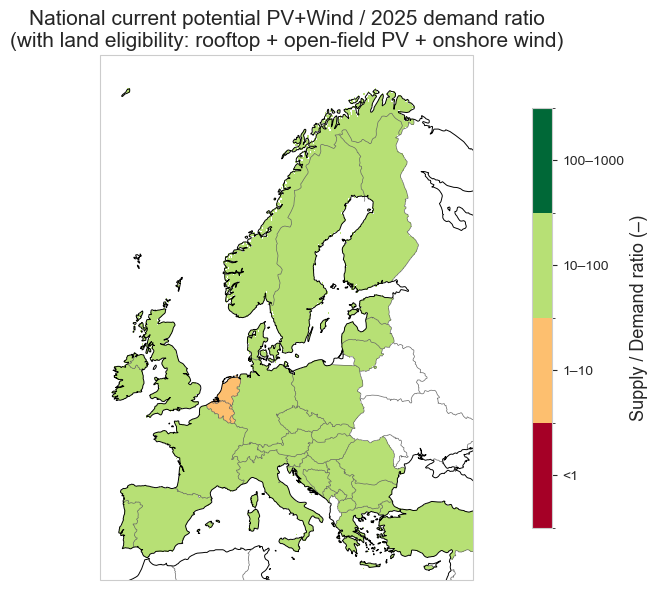

In [76]:

_fs = components_size_renewables_demand

# ── Plot national supply / demand ratio — with land eligibility ───────────────
bounds_elig = [0, 1, 10, 100, 1000]
if ds_national_elig["ratio"].max() > bounds_elig[-1]:
    bounds_elig.append(ds_national_elig["ratio"].max() * 1.1)
labels_elig = ["<1", "1–10", "10–100", "100–1000"]
if len(bounds_elig) > len(labels_elig) + 1:
    labels_elig.append(f">{bounds_elig[-2]:.0f}")
n_bins_elig = len(bounds_elig) - 1
cmap_elig = plt.get_cmap("RdYlGn", n_bins_elig)
norm_elig = mcolors.BoundaryNorm(bounds_elig, ncolors=n_bins_elig, clip=True)

# Paint each cell with its country's ratio value
da_ratio_elig = xr.full_like(mask_countries_worldpop, fill_value=np.nan, dtype=float)
for region in countries.regions.values():
    if region.name in ds_national_elig.index:
        da_ratio_elig = xr.where(
            mask_countries_worldpop == region.number,
            ds_national_elig.loc[region.name, "ratio"],
            da_ratio_elig,
        )

fig, ax = plt.subplots(
    figsize=(12, 6),
    subplot_kw={"projection": ccrs.Mercator()},
)

img = da_ratio_elig.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=cmap_elig,
    norm=norm_elig,
    add_colorbar=False,
)

cbar = fig.colorbar(
    img,
    ax=ax,
    orientation="vertical",
    ticks=[(bounds_elig[i] + bounds_elig[i + 1]) / 2 for i in range(n_bins_elig)],
    shrink=0.8,
)
cbar.ax.set_yticklabels(labels_elig, fontsize=_fs["FONTSIZE_TICKS"])
cbar.set_label("Supply / Demand ratio (–)", fontsize=_fs["FONTSIZE_LABELS"])

ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="0.4")
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.set_title(
    "National current potential PV+Wind / 2025 demand ratio\n(with land eligibility: rooftop + open-field PV + onshore wind)",
    fontsize=_fs["FONTSIZE_TITLE"],
)
plt.tight_layout()

plt.savefig(path_figs / "energy" / "supply_demand" / "national_supply_demand_ratio_elig.png", dpi=300)
plt.show()


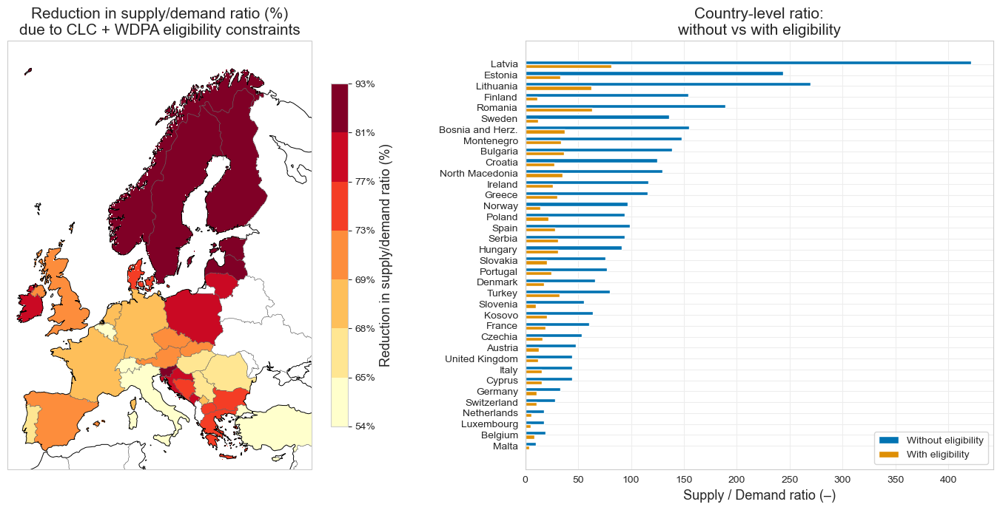

In [77]:

_fs = components_size_renewables_demand

# ── Impact of land eligibility on supply / demand ratio ──────────────────────
# Δratio = ds_national["ratio"] − ds_national_elig["ratio"]
#   Positive → potential cut by eligibility constraints (CLC + WDPA)
common = ds_national.index.intersection(ds_national_elig.index)

compare = pd.DataFrame({
    "without_elig": ds_national.loc[common, "ratio"],
    "with_elig":    ds_national_elig.loc[common, "ratio"],
}).dropna()
compare["diff"]     = compare["without_elig"] - compare["with_elig"]
compare["diff_pct"] = compare["diff"] / compare["without_elig"] * 100
compare = compare.sort_values("diff", ascending=True)

# ── Choropleth of Δratio (%) ──────────────────────────────────────────────────
da_diff_pct = xr.full_like(mask_countries_worldpop, fill_value=np.nan, dtype=float)
for region in countries.regions.values():
    if region.name in compare.index:
        da_diff_pct = xr.where(
            mask_countries_worldpop == region.number,
            compare.loc[region.name, "diff_pct"],
            da_diff_pct,
        )

n_bins_pct = 7
bounds_pct = np.percentile(compare["diff_pct"].dropna(), np.linspace(0, 100, n_bins_pct + 1))
cmap_pct   = plt.get_cmap("YlOrRd", n_bins_pct)
norm_pct   = mcolors.BoundaryNorm(bounds_pct, ncolors=n_bins_pct, clip=True)

fig, axes = plt.subplots(
    1, 2,
    figsize=(20, 7),
    gridspec_kw={"width_ratios": [2, 1]},
    subplot_kw={"projection": ccrs.Mercator()},
)
fig.delaxes(axes[1])
ax_map = axes[0]
ax_bar = fig.add_subplot(1, 2, 2)   # plain Axes for bar chart

img = sel_extent(da_diff_pct, extent=extent).plot(
    ax=ax_map,
    transform=ccrs.PlateCarree(),
    cmap=cmap_pct,
    norm=norm_pct,
    add_colorbar=False,
)
cbar = fig.colorbar(img, ax=ax_map, orientation="vertical", shrink=0.8, pad=0.02)
cbar.set_ticks(bounds_pct)
cbar.set_ticklabels([f"{v:.0f}%" for v in bounds_pct], fontsize=_fs["FONTSIZE_TICKS"])
cbar.set_label("Reduction in supply/demand ratio (%)", fontsize=_fs["FONTSIZE_LABELS"])
ax_map.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="0.4")
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax_map.set_title(
    "Reduction in supply/demand ratio (%)\ndue to CLC + WDPA eligibility constraints",
    fontsize=_fs["FONTSIZE_TITLE"],
)

# ── Right panel: horizontal bar chart — absolute ratio values ─────────────────
y      = np.arange(len(compare))
height = 0.35
ax_bar.barh(y + height / 2, compare["without_elig"], height, color=sns.color_palette("colorblind")[0], label="Without eligibility")
ax_bar.barh(y - height / 2, compare["with_elig"],    height, color=sns.color_palette("colorblind")[1], label="With eligibility")
ax_bar.set_yticks(y)
ax_bar.set_yticklabels(compare.index, fontsize=_fs["FONTSIZE_TICKS"])
ax_bar.set_xlabel("Supply / Demand ratio (–)", fontsize=_fs["FONTSIZE_LABELS"])
ax_bar.set_title("Country-level ratio:\nwithout vs with eligibility", fontsize=_fs["FONTSIZE_TITLE"])
ax_bar.legend(fontsize=_fs["FONTSIZE_LEGEND"])

plt.tight_layout()
plt.savefig(path_figs / "energy" / "supply_demand" / "national_supply_demand_ratio_diff.png", dpi=300, bbox_inches="tight")
plt.show()


#### With future climate

In [78]:

eligibility_clc = sel_extent(
    xr.open_dataset(
        path_data_processed / "maps" / "land_eligibility" / "land_eligibility_with_wdpa.nc"
    ).rename({"x": "lon", "y": "lat"}),
    extent=extent,
)

pd_pv = apply_land_mask(pv_power_density(
    pv_config=ROOFTOP_PV_CONFIGURATION,
    built_up_fraction=eligibility_clc["built_up_fraction"],
    eligible_pv_openfield=eligibility_clc["eligible_fraction_pv_openfield"],
))

wind_result = wind_power_density("E-126/7580", hub_height_m=EUROPE_HUB_HEIGHTS["E-126/7580"])
pd_wind = wind_result["power_density_MW_km2"]


Wind turbine: E-126/7580  |  hub height: 127 m
  Rotor diameter   : 127.0 m
  Rated power      : 7.58 MW
  Layout           : 4.0D × 8.0D
  Area / turbine   : 0.5161 km²
  Power density    : 14.69 MW/km²

  Sensitivity to spacing (MW/km²):
    3.0D×7.0D  :   22.4
    3.0D×8.0D  :   19.6
    3.0D×9.0D  :   17.4
    4.0D×7.0D  :   16.8
    4.0D×8.0D  :   14.7 ← selected
    4.0D×9.0D  :   13.1
    5.0D×7.0D  :   13.4
    5.0D×8.0D  :   11.8
    5.0D×9.0D  :   10.4


In [79]:
# ── Generation potential [MWh/yr/km²] ────────────────────────────────
# pd_pv already encodes both rooftop and open-field contributions in
# MW/km²_cell, so no additional eligibility fraction multiplication is needed.
fraction_wind =  0.2  # Assume 30% of land can be used for wind

gen_pv = (
    pd_pv * mean_mid_century["pv"].mean("model") * 8760
)
gen_wind = (
    eligibility_clc["eligible_fraction_wind"] * fraction_wind
    * pd_wind
    * mean_mid_century["wind"].mean("model")
    * 8760
)
ratio = (gen_pv + gen_wind) / da_demand_gridded

# ── National supply / demand ratio — with land eligibility ───────────────────
# gen_pv [MWh/yr/km²_cell] and gen_wind [MWh/yr/km²_cell] already embed
# eligibility fractions in their power densities. Multiply by cell area to
# get total supply [MWh/yr] per cell, then aggregate to national totals.

# Build a country mask on the eligibility grid
cell_area_elig = cell_area_km2(gen_pv)  # km² per cell on eligibility grid

supply_gridded_elig = (gen_pv + gen_wind) * cell_area_elig  # MWh / yr per cell

national_supply_elig = {}
for region in countries.regions.values():
    mask = mask_countries_worldpop == region.number
    country_supply = float(supply_gridded_elig.where(mask).sum(skipna=True).values)
    if country_supply > 0:
        national_supply_elig[region.name] = country_supply

ds_national_elig_mid_century = pd.DataFrame(
    {
        "supply_MWh": pd.Series(national_supply_elig),
        "demand_MWh": demand_by_country,
    }
).dropna()

ds_national_elig_mid_century["ratio"] = ds_national_elig_mid_century["supply_MWh"] / ds_national_elig_mid_century["demand_MWh"]
ds_national_elig_mid_century = ds_national_elig_mid_century.sort_values("ratio")
ds_national_elig_mid_century

,supply_MWh,demand_MWh,ratio
Malta,1.160424e+07,3230000.0,3.592643
Luxembourg,3.816953e+07,6700000.0,5.696945
Netherlands,7.239493e+08,121110000.0,5.977618
Belgium,8.024213e+08,86560000.0,9.270116
Slovenia,1.514733e+08,14310000.0,10.585135
Germany,5.638630e+09,520270000.0,10.837892
Switzerland,7.217685e+08,65120000.0,11.083668
Finland,1.015567e+09,87580000.0,11.595876
Sweden,1.679847e+09,137110000.0,12.251820
United Kingdom,4.028405e+09,321850000.0,12.516405


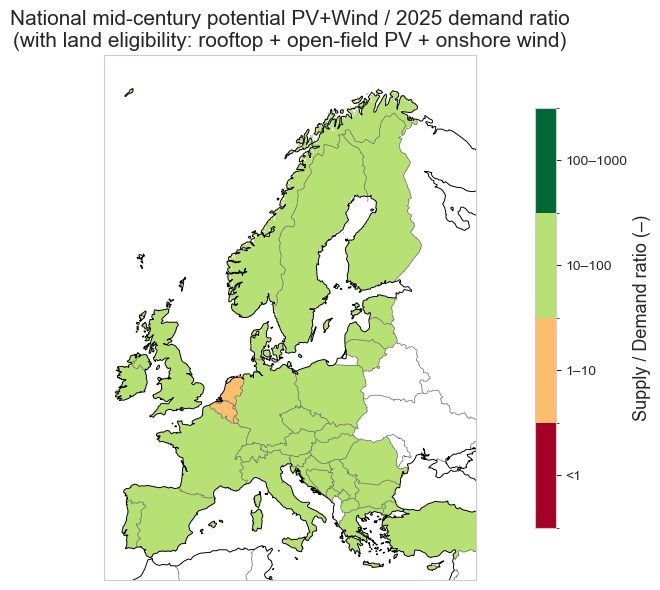

In [80]:

_fs = components_size_renewables_demand

# ── Plot national supply / demand ratio — with land eligibility ───────────────
bounds_elig = [0, 1, 10, 100, 1000]
if ds_national_elig_mid_century["ratio"].max() > bounds_elig[-1]:
    bounds_elig.append(ds_national_elig_mid_century["ratio"].max() * 1.1)
labels_elig = ["<1", "1–10", "10–100", "100–1000"]
if len(bounds_elig) > len(labels_elig) + 1:
    labels_elig.append(f">{bounds_elig[-2]:.0f}")
n_bins_elig = len(bounds_elig) - 1
cmap_elig = plt.get_cmap("RdYlGn", n_bins_elig)
norm_elig = mcolors.BoundaryNorm(bounds_elig, ncolors=n_bins_elig, clip=True)

# Paint each cell with its country's ratio value
da_ratio_elig = xr.full_like(mask_countries_worldpop, fill_value=np.nan, dtype=float)
for region in countries.regions.values():
    if region.name in ds_national_elig_mid_century.index:
        da_ratio_elig = xr.where(
            mask_countries_worldpop == region.number,
            ds_national_elig_mid_century.loc[region.name, "ratio"],
            da_ratio_elig,
        )

fig, ax = plt.subplots(
    figsize=(12, 6),
    subplot_kw={"projection": ccrs.Mercator()},
)

img = da_ratio_elig.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=cmap_elig,
    norm=norm_elig,
    add_colorbar=False,
)

cbar = fig.colorbar(
    img,
    ax=ax,
    orientation="vertical",
    ticks=[(bounds_elig[i] + bounds_elig[i + 1]) / 2 for i in range(n_bins_elig)],
    shrink=0.8,
)
cbar.ax.set_yticklabels(labels_elig, fontsize=_fs["FONTSIZE_TICKS"])
cbar.set_label("Supply / Demand ratio (–)", fontsize=_fs["FONTSIZE_LABELS"])

ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="0.4")
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.set_title(
    "National mid-century potential PV+Wind / 2025 demand ratio\n(with land eligibility: rooftop + open-field PV + onshore wind)",
    fontsize=_fs["FONTSIZE_TITLE"],
)
plt.tight_layout()

plt.savefig(path_figs / "energy" / "supply_demand" / "national_supply_demand_ratio_elig_mid_century.png", dpi=300)
plt.show()


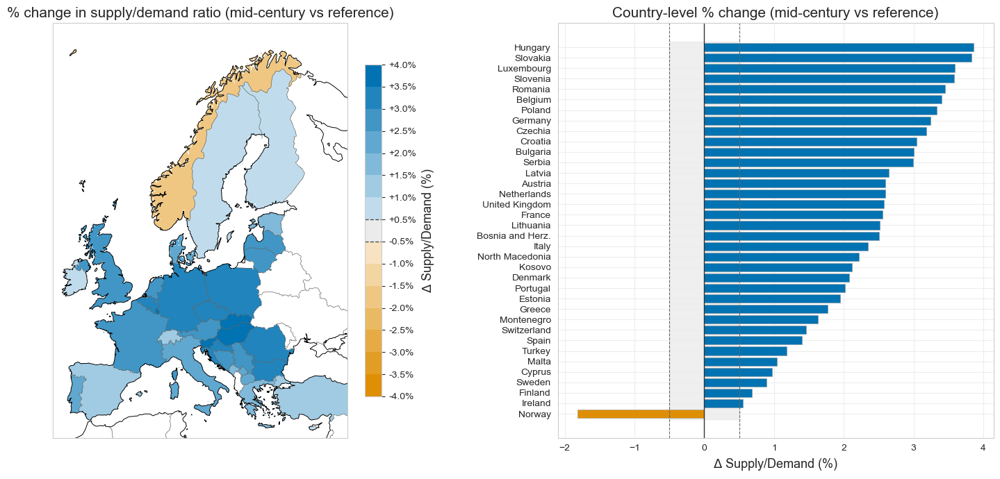

In [81]:

_fs = components_size_renewables_demand

# ── Current vs mid-century supply/demand ratio: % change ─────────────────────
# diff_pct = (mid_century − current) / current × 100
common = ds_national.index.intersection(ds_national_elig.index)

compare = pd.DataFrame({
    "current":     ds_national_elig.loc[common, "ratio"],
    "mid_century": ds_national_elig_mid_century.loc[common, "ratio"],
}).dropna()
compare["diff"]     = compare["mid_century"] - compare["current"]
compare["diff_pct"] = compare["diff"] / compare["current"] * 100
compare = compare.sort_values("diff_pct", ascending=True)

# ── Symmetric diverging colormap with 0.5 % steps ────────────────────────────
STEP              = 0.5
NEUTRAL_THRESHOLD = 0.5
VMAX_PCT          = max(abs(compare["diff_pct"].min()), abs(compare["diff_pct"].max()))
vmax_rounded      = np.ceil(VMAX_PCT / STEP) * STEP
n_side            = int(round((vmax_rounded - NEUTRAL_THRESHOLD) / STEP))

_cb = sns.color_palette("colorblind")
_color_neg = np.array([*_cb[1], 1.0])
_color_pos = np.array([*_cb[0], 1.0])
_color_neu = np.array([0.92, 0.92, 0.92, 1.0])
_white     = np.array([1.0, 1.0, 1.0, 1.0])

neg_colors = np.array([_white * (1 - t) + _color_neg * t for t in np.linspace(0.25, 1.0, n_side)])
pos_colors = np.array([_white * (1 - t) + _color_pos * t for t in np.linspace(0.25, 1.0, n_side)])
all_colors = np.vstack([neg_colors[::-1], [_color_neu], pos_colors])
cmap_pct   = mcolors.ListedColormap(all_colors)

bounds_neg = list(np.arange(-vmax_rounded, -NEUTRAL_THRESHOLD + STEP * 0.1, STEP))
bounds_pos = list(np.arange( NEUTRAL_THRESHOLD,  vmax_rounded + STEP * 0.1, STEP))
bounds_pct = bounds_neg + bounds_pos
norm_pct   = mcolors.BoundaryNorm(bounds_pct, ncolors=len(all_colors))

# ── Left panel: choropleth (% change) ────────────────────────────────────────
da_pct = xr.full_like(mask_countries_worldpop, fill_value=np.nan, dtype=float)
for region in countries.regions.values():
    if region.name in compare.index:
        da_pct = xr.where(
            mask_countries_worldpop == region.number,
            compare.loc[region.name, "diff_pct"],
            da_pct,
        )

fig, axes = plt.subplots(
    1, 2,
    figsize=(20, 7),
    gridspec_kw={"width_ratios": [2, 1]},
    subplot_kw={"projection": ccrs.Mercator()},
)
fig.delaxes(axes[1])
ax_map = axes[0]
ax_bar = fig.add_subplot(1, 2, 2)

img = sel_extent(da_pct, extent=extent).plot(
    ax=ax_map,
    transform=ccrs.PlateCarree(),
    cmap=cmap_pct,
    norm=norm_pct,
    add_colorbar=False,
)
cbar = fig.colorbar(img, ax=ax_map, orientation="vertical", shrink=0.8, pad=0.02)
cbar.set_ticks(bounds_pct)
cbar.set_ticklabels([f"{v:+.1f}%" for v in bounds_pct], fontsize=_fs["FONTSIZE_TICKS"])
cbar.set_label(r"$\Delta$ Supply/Demand (%)", fontsize=_fs["FONTSIZE_LABELS"])
for tick in [-NEUTRAL_THRESHOLD, NEUTRAL_THRESHOLD]:
    cbar.ax.axhline(tick, color="0.3", linewidth=1.0, linestyle="--")
ax_map.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="0.4")
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax_map.set_title(
    "% change in supply/demand ratio (mid-century vs reference)",
    fontsize=_fs["FONTSIZE_TITLE"],
)

# ── Right panel: bar chart (% change, coloured by direction) ─────────────────
bar_colors = [
    tuple(_color_neg[:3]) if d < -NEUTRAL_THRESHOLD else
    tuple(_color_pos[:3]) if d >  NEUTRAL_THRESHOLD else
    tuple(_color_neu[:3])
    for d in compare["diff_pct"]
]
y = np.arange(len(compare))
ax_bar.barh(y, compare["diff_pct"], color=bar_colors, edgecolor="0.6", linewidth=0.4)
ax_bar.axvline(-NEUTRAL_THRESHOLD, color="0.4", linestyle="--", linewidth=0.8)
ax_bar.axvline( NEUTRAL_THRESHOLD, color="0.4", linestyle="--", linewidth=0.8)
ax_bar.axvline(0, color="0.2", linestyle="-", linewidth=1.0)
ax_bar.fill_betweenx(
    [-0.5, len(compare) - 0.5], -NEUTRAL_THRESHOLD, NEUTRAL_THRESHOLD,
    color="0.85", alpha=0.4, zorder=0,
)
ax_bar.set_yticks(y)
ax_bar.set_yticklabels(compare.index, fontsize=_fs["FONTSIZE_TICKS"])
ax_bar.set_xlabel(r"$\Delta$ Supply/Demand (%)", fontsize=_fs["FONTSIZE_LABELS"])
ax_bar.set_title(
    "Country-level % change (mid-century vs reference)",
    fontsize=_fs["FONTSIZE_TITLE"],
)

plt.tight_layout()
plt.savefig(
    path_figs / "energy" / "supply_demand" / "national_supply_demand_ratio_pct_change.png",
    dpi=300, bbox_inches="tight",
)
plt.show()


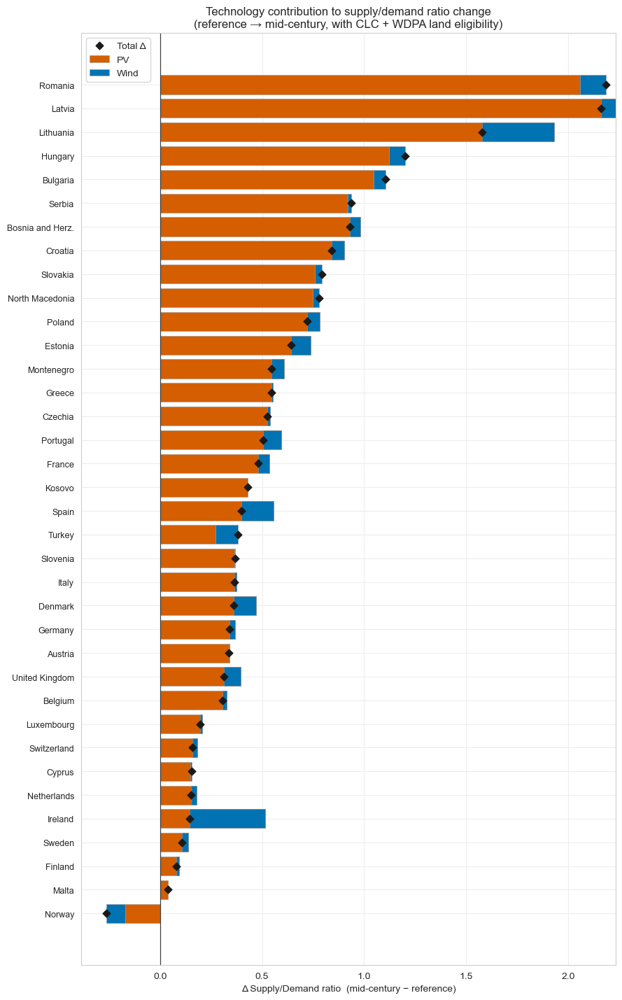

In [ ]:

# ── Technology decomposition of Δ(supply/demand) : reference → mid-century ───
# Δratio_total = Δratio_pv + Δratio_wind
#   where Δratio_X = (national_supply_X_mid - national_supply_X_ref) / demand
#
# pd_pv and eligibility_clc are the same for both periods (same land cover).
# Only the climate capacity-factor means (mean_ref / mean_mid_century) differ.

gen_pv_ref   = pd_pv * mean_ref["pv"].mean("model") * 8760
gen_wind_ref = (eligibility_clc["eligible_fraction_wind"] * fraction_wind
                * pd_wind * mean_ref["wind"].mean("model") * 8760)

gen_pv_mid   = pd_pv * mean_mid_century["pv"].mean("model") * 8760
gen_wind_mid = (eligibility_clc["eligible_fraction_wind"] * fraction_wind
                * pd_wind * mean_mid_century["wind"].mean("model") * 8760)

def _national_supply_MWh(gen_da):
    """Sum gridded generation [MWh yr⁻¹ km⁻²] × cell area → national [MWh yr⁻¹]."""
    out = {}
    for region in countries.regions.values():
        mask = mask_countries_worldpop == region.number
        val  = float((gen_da * cell_area_elig).where(mask).sum(skipna=True).values)
        if val > 0:
            out[region.name] = val
    return pd.Series(out)

ns_pv_ref   = _national_supply_MWh(gen_pv_ref)
ns_wind_ref = _national_supply_MWh(gen_wind_ref)
ns_pv_mid   = _national_supply_MWh(gen_pv_mid)
ns_wind_mid = _national_supply_MWh(gen_wind_mid)

common_dec = (
    demand_by_country.index
    .intersection(ns_pv_ref.index)
    .intersection(ns_pv_mid.index)
)

decomp = pd.DataFrame({
    "Δratio_pv":   (ns_pv_mid.loc[common_dec]   - ns_pv_ref.loc[common_dec])   / demand_by_country.loc[common_dec],
    "Δratio_wind": (ns_wind_mid.loc[common_dec] - ns_wind_ref.loc[common_dec]) / demand_by_country.loc[common_dec],
}).dropna()
decomp["Δratio_total"] = decomp["Δratio_pv"] + decomp["Δratio_wind"]
decomp = decomp.sort_values("Δratio_total", ascending=True)

# ── Stacked horizontal bar chart ──────────────────────────────────────────────
_fs = components_size_renewables_demand
_cb = sns.color_palette("colorblind")
fig, ax = plt.subplots(figsize=(9, max(5, len(decomp) * 0.40)))
y = np.arange(len(decomp))

ax.barh(y, decomp["Δratio_pv"],   color=_cb[3], label="PV",   edgecolor="0.6", linewidth=0.4)
ax.barh(y, decomp["Δratio_wind"], color=_cb[0], label="Wind", edgecolor="0.6", linewidth=0.4,
        left=decomp["Δratio_pv"].values)
ax.scatter(decomp["Δratio_total"], y, color="0.1", zorder=5, s=30, label="Total Δ", marker="D")

ax.axvline(0, color="0.25", linewidth=0.9)
ax.set_yticks(y)
ax.set_yticklabels(decomp.index, fontsize=_fs["FONTSIZE_TICKS"])
ax.set_xlabel("Δ Supply/Demand ratio  (mid-century − reference)", fontsize=_fs["FONTSIZE_LABELS"])
ax.set_title(
    "Technology contribution to supply/demand ratio change\n"
    "(reference → mid-century, with CLC + WDPA land eligibility)",
    fontsize=_fs["FONTSIZE_TITLE"],
)
ax.legend(fontsize=_fs["FONTSIZE_LEGEND"])
plt.tight_layout()
plt.savefig(
    path_figs / "energy" / "supply_demand" / "national_supply_demand_decomp_pv_wind.png",
    dpi=300, bbox_inches="tight",
)

plt.show()

### Levelised cost of energy

In [87]:

# ── LCOE from capital and O&M costs (IEA WEO 2025) ───────────────────────────
#
# Standard levelised-cost formula:
#
#   LCOE [$/MWh] = (CAPEX [$/kW] × CRF  +  FOM [$/kW yr⁻¹])   +  VOM [$/MWh]
#                  ─────────────────────────────────────────────
#                          CF  ×  8760  [h yr⁻¹]
#
#   Capital Recovery Factor:  CRF = r(1+r)ⁿ / ((1+r)ⁿ − 1)

# ── EU-27 member states (Natural Earth names used by regionmask) ──────────────
EU_27 = {
    "Austria", "Belgium", "Bulgaria", "Croatia", "Cyprus",
    "Czechia", "Denmark", "Estonia", "Finland", "France",
    "Germany", "Greece", "Hungary", "Ireland", "Italy",
    "Latvia", "Lithuania", "Luxembourg", "Malta", "Netherlands",
    "Poland", "Portugal", "Romania", "Slovakia", "Slovenia",
    "Spain", "Sweden",
}

def lcoe_from_costs(
    capex_usd_kw: float,
    fom_usd_kw_yr: float,
    capacity_factor: float,
    vom_usd_mwh: float = 0.0,
    discount_rate: float = 0.07,
    lifetime_yr: int = 25,
    usd_to_eur: float = 1.0,
) -> float:
    """
    Compute LCOE [currency/MWh] from plant cost data.

    Parameters
    ----------
    capex_usd_kw      Overnight capital cost [$/kW]
    fom_usd_kw_yr     Fixed O&M cost [$/kW yr⁻¹]
    capacity_factor   Annual full-load fraction [–]
    vom_usd_mwh       Variable O&M [$/MWh]  (default 0)
    discount_rate     Nominal WACC [–]        (default 7 %)
    lifetime_yr       Economic plant lifetime [yr]  (default 25)
    usd_to_eur        Exchange rate (1 USD → X EUR); set to 1.0 to keep in USD

    Returns
    -------
    LCOE in the same currency unit per MWh as the inputs (after conversion).
    """
    crf = discount_rate * (1 + discount_rate) ** lifetime_yr / (
        (1 + discount_rate) ** lifetime_yr - 1
    )
    annual_cost_per_kw   = capex_usd_kw * crf + fom_usd_kw_yr   # $/kW yr⁻¹
    annual_energy_per_kw = capacity_factor * 8760 / 1000         # MWh yr⁻¹ per kW

    lcoe_usd = annual_cost_per_kw / annual_energy_per_kw + vom_usd_mwh
    return round(lcoe_usd * usd_to_eur, 2)


# ── IEA WEO 2025 — EU values (replace with exact figures from your table) ─────
# Source: IEA World Energy Outlook 2025, Annex — Capital Cost and Performance
#         Characteristics, European Union, STEPS scenario, 2025.
# Exchange rate: ~1 USD = 0.92 EUR (2024 annual average)
USD_TO_EUR = 0.92

# Note: IEA WEO 2025 provides separate CAPEX and FOM for rooftop PV and open-field PV.
capex_pv_open_field = 760   # $/kW
capex_pv_rooftop    = 1000  # $/kW
capex_pv_avg        = (capex_pv_open_field + capex_pv_rooftop) / 2

fom_usd_kw_yr_pv_open_field = 12    # $/kW yr⁻¹
fom_usd_kw_yr_pv_rooftop    = 14    # $/kW yr⁻¹
fom_usd_kw_yr_pv_avg        = (fom_usd_kw_yr_pv_open_field + fom_usd_kw_yr_pv_rooftop) / 2

capacity_factor_pv_open_field = 0.14
capacity_factor_pv_rooftop    = 0.13
capacity_factor_pv_avg        = (capacity_factor_pv_open_field + capacity_factor_pv_rooftop) / 2

LCOE_PV_EUR_MWH = lcoe_from_costs(
    capex_usd_kw    = capex_pv_avg,
    fom_usd_kw_yr   = fom_usd_kw_yr_pv_avg,
    capacity_factor = capacity_factor_pv_avg,
    vom_usd_mwh     = 0.0,
    discount_rate   = 0.07,
    lifetime_yr     = 25,
    usd_to_eur      = USD_TO_EUR,
)

capex_wind_onshore           = 1620  # $/kW
fom_usd_kw_yr_wind_onshore   = 40   # $/kW yr⁻¹
capacity_factor_wind_onshore = 0.29

LCOE_WIND_EUR_MWH = lcoe_from_costs(
    capex_usd_kw    = capex_wind_onshore,
    fom_usd_kw_yr   = fom_usd_kw_yr_wind_onshore,
    capacity_factor = capacity_factor_wind_onshore,
    vom_usd_mwh     = 0.0,
    discount_rate   = 0.07,
    lifetime_yr     = 25,
    usd_to_eur      = USD_TO_EUR,
)

print(
    f"Derived LCOE (IEA WEO 2025, EU, WACC=7 %, 25 yr, 1 USD = {USD_TO_EUR} EUR):\n"
    f"  Solar PV     : {LCOE_PV_EUR_MWH:.1f} €/MWh\n"
    f"  Onshore wind : {LCOE_WIND_EUR_MWH:.1f} €/MWh"
)

# ── Effective LCOE to cover national electricity demand ───────────────────────

def _lcoe_df(ns_pv, ns_wind, ds_national_period, label):
    """Effective LCOE [€/MWh_demand] and annual cost [€ bn/yr] per country."""
    idx = (
        ns_pv.index
        .intersection(ns_wind.index)
        .intersection(ds_national_period.index)
    )
    pv_supply   = ns_pv.loc[idx]
    wind_supply = ns_wind.loc[idx]
    ratio_vals  = ds_national_period.loc[idx, "ratio"]
    demand_vals = ds_national_period.loc[idx, "demand_MWh"]

    total_cost = pv_supply * LCOE_PV_EUR_MWH + wind_supply * LCOE_WIND_EUR_MWH  # €/yr

    return pd.DataFrame({
        f"effective_LCOE_{label}":  total_cost / (ratio_vals * demand_vals),
        f"annual_cost_bn_{label}":  total_cost / ratio_vals / 1e9,
        f"PV_cost_share_{label}":   pv_supply   * LCOE_PV_EUR_MWH   / total_cost,
        f"Wind_cost_share_{label}": wind_supply * LCOE_WIND_EUR_MWH / total_cost,
    }).dropna()

lcoe_ref  = _lcoe_df(ns_pv_ref, ns_wind_ref, ds_national_elig,             "ref")
lcoe_mid  = _lcoe_df(ns_pv_mid, ns_wind_mid, ds_national_elig_mid_century, "mid")

lcoe_both = lcoe_ref.join(lcoe_mid, how="inner")

# ── Filter to EU-27 only ──────────────────────────────────────────────────────
in_data    = set(lcoe_both.index)
eu_present = EU_27 & in_data
eu_missing = EU_27 - in_data
non_eu     = in_data - EU_27

if eu_missing:
    print(f"\n⚠  EU-27 countries missing from data ({len(eu_missing)}):")
    for c in sorted(eu_missing):
        print(f"   • {c}")
else:
    print(f"\n✓  All 27 EU member states present in data.")

if non_eu:
    print(f"\nℹ  Non-EU countries excluded ({len(non_eu)}): {', '.join(sorted(non_eu))}")

lcoe_both = lcoe_both.loc[sorted(eu_present)]
lcoe_both = lcoe_both.sort_values("effective_LCOE_ref", ascending=False)

print(f"\nCountry-level effective LCOE and annual cost (EU-27):")
lcoe_both[["effective_LCOE_ref", "effective_LCOE_mid", "annual_cost_bn_ref", "annual_cost_bn_mid"]]


Derived LCOE (IEA WEO 2025, EU, WACC=7 %, 25 yr, 1 USD = 0.92 EUR):
  Solar PV     : 68.9 €/MWh
  Onshore wind : 64.8 €/MWh

✓  All 27 EU member states present in data.

ℹ  Non-EU countries excluded (9): Bosnia and Herz., Kosovo, Montenegro, North Macedonia, Norway, Serbia, Switzerland, Turkey, United Kingdom

Country-level effective LCOE and annual cost (EU-27):


,effective_LCOE_ref,effective_LCOE_mid,annual_cost_bn_ref,annual_cost_bn_mid
Malta,68.693709,68.697746,0.221881,0.221894
Cyprus,68.685758,68.686131,0.405933,0.405935
Slovenia,68.575420,68.584421,0.981314,0.981443
Italy,68.509397,68.519950,21.347528,21.350817
Austria,68.496360,68.506430,5.194764,5.195528
Bulgaria,68.489022,68.493987,2.501904,2.502085
Greece,68.464657,68.472505,3.803896,3.804332
Luxembourg,68.456600,68.476579,0.458659,0.458793
Slovakia,68.429554,68.438965,1.830491,1.830742
Portugal,68.408817,68.431865,4.134629,4.136022


In [88]:
lcoe_both["annual_cost_bn_ref"].sum()

189.3924059712528

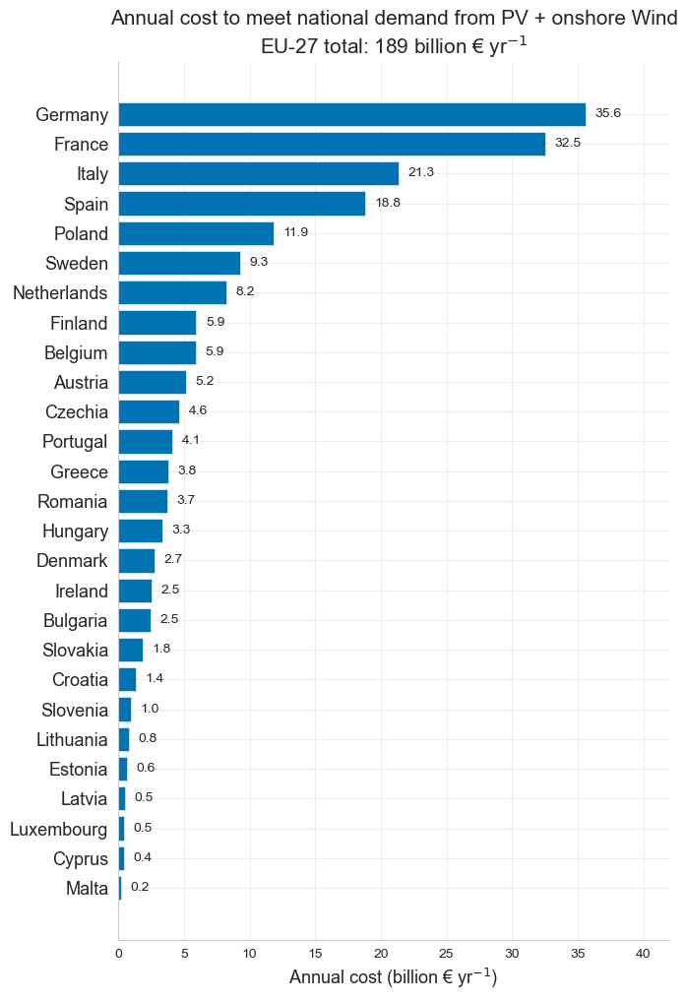

In [92]:

# ── Annual cost (reference period) — EU-27 bar chart ─────────────────────────
_fs = components_size_renewables_demand
data = lcoe_both["annual_cost_bn_ref"].sort_values(ascending=True)
total_eu = data.sum()

fig, ax = plt.subplots(figsize=(7, max(5, len(data) * 0.38)))

bar_color = sns.color_palette("colorblind")[0]
bars = ax.barh(data.index, data.values, color=bar_color, edgecolor="white", linewidth=0.4)

# Value labels
for bar, val in zip(bars, data.values):
    ax.text(
        val + 0.02 * data.max(),
        bar.get_y() + bar.get_height() / 2,
        f"{val:.1f}",
        va="center", ha="left", fontsize=_fs["FONTSIZE_TICKS"],
    )

ax.set_xlabel("Annual cost (billion € yr$^{-1}$)", fontsize=_fs["FONTSIZE_LABELS"])
ax.set_xlim(0, data.max() * 1.18)
ax.set_title(
    f"Annual cost to meet national demand from PV + onshore Wind\n"
    rf"EU-27 total: {total_eu:.0f} billion € yr$^{{-1}}$",
    fontsize=_fs["FONTSIZE_TITLE"],
)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="y", labelsize=_fs["FONTSIZE_LABELS"])
plt.tight_layout()
plt.show()


# Switzerland

In [50]:
selected_turbine_ch = ch_turbines[0]
selected_pv_tilt_azimuth_ch = "tilt_35_azimuth_S"

In [51]:
ds_orog_cnrm_ch = sel_extent(
    xr.open_dataset(
        sorted(
            (path_data_processed / "cordex_processed").glob("CNRM*/regridded/fx/*.nc")
        )[0]
    ),
    EXTENT_CH,
)

## Load data

In [55]:
gdf_regions_ch = gpd.read_file(
    path_data_processed / "maps" / "regions_ch" / "PRODREG.shp"
).to_crs("EPSG:4326")
regions_ch = regionmask.from_geopandas(gdf_regions_ch, names="ProdregN_3")
regions_ch_mask = regions_ch.mask(ds_orog_cnrm_ch.orog)

## Analysis

In [ ]:
mean_ref_ch = sel_extent(
    xr.open_dataset(
        path_data_processed / "energy" / "analysis" / "annual" / "period" / "mean_reference_period_ch.nc"
    ).sel(model=valid_models),
    extent=EXTENT_CH,
)
mean_ref_ch = mean_ref_ch[
    ["pv", "wind", "hydropower_ror", "hydropower_reservoir", "CDD", "HDD"]
]
mean_ref_ch["hydropower_ror"] = mean_ref_ch["hydropower_ror"] * 1e-6
mean_mid_century_ch = sel_extent(
    xr.open_dataset(
        path_data_processed / "energy" / "analysis" / "annual" / "period" / "mean_mid_century_ch.nc"
    ).sel(model=valid_models),
    extent=EXTENT_CH,
)
mean_mid_century_ch = mean_mid_century_ch[
    ["pv", "wind", "hydropower_ror", "hydropower_reservoir", "CDD", "HDD"]
]
mean_mid_century_ch["hydropower_ror"] = mean_mid_century_ch["hydropower_ror"] * 1e-6

In [57]:
# Apply the mask to all variables in mean_ref
for var in ["pv", "hydropower_ror", "hydropower_reservoir", "HDD", "CDD"]:
    if var in mean_ref_ch.data_vars:
        mean_ref_ch[var] = apply_land_mask(mean_ref_ch[var])

# Repeat for mean_mid_century if needed:
for var in ["pv", "hydropower_ror", "hydropower_reservoir", "HDD", "CDD"]:
    if var in mean_mid_century_ch.data_vars:
        mean_mid_century_ch[var] = apply_land_mask(mean_mid_century_ch[var])

In [58]:
(((mean_mid_century_ch - mean_ref_ch) / mean_ref_ch) * 100).mean(
    dim=["lat", "lon"]
).to_dataframe()

,band,spatial_ref,pv,wind,hydropower_ror,hydropower_reservoir,CDD,HDD
model,,,,,,,,
CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85,1,0,1.077882,-0.778094,7.548622,8.408993,inf,-12.066667
CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1_rcp85,1,0,-0.220418,-1.402812,4.674764,5.556756,inf,-14.501923
CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85,1,0,-0.633459,2.557742,4.244639,5.956927,inf,-11.144774
CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1_rcp85,1,0,2.761926,-4.258751,-5.826632,-5.568762,inf,-11.611929
MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85,1,0,3.184005,-3.522555,4.917571,5.485253,inf,-13.223893
MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1_rcp85,1,0,2.419236,0.764408,12.786683,16.155609,inf,-14.931634
MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85,1,0,4.441167,-3.001697,-8.640751,-8.914995,inf,-15.594134
MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1_rcp85,1,0,2.329901,-1.727306,7.859539,10.480243,inf,-13.153742
MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1_rcp85,1,0,4.006920,-6.817144,-5.358680,-4.833958,inf,-11.628865


In [59]:
regional_stats_seasonal = xr.open_dataset(
    path_data_processed / "energy" / "ch" / "statistics" / "regional_stats_seasonal.nc"
).sel(model=valid_models)
regional_stats_yearly = xr.open_dataset(
    path_data_processed / "energy" / "ch" / "statistics" / "regional_stats_yearly.nc"
).sel(model=valid_models)
regional_stats_yearly["mask"] = [
    "Swiss " + r if r != "Switzerland" else r for r in regional_stats_yearly.mask.values
]

regional_stats_yearly["hydropower_ror"] = regional_stats_yearly["hydropower_ror"] * 1e-6
regional_stats_seasonal["hydropower_ror"] = (
    regional_stats_seasonal["hydropower_ror"] * 1e-6
)

In [ ]:
regional_stats_climate_yearly = xr.open_dataset(path_data_processed / "energy" / "ch" / "statistics" / "regional_stats_climate_seasonal.nc").sel(mask="Alps")

<xarray.Dataset> Size: 115kB
Dimensions:      (time: 441, model: 9)
Coordinates:
  * model        (model) <U48 2kB 'CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1...
  * time         (time) datetime64[ns] 4kB 1990-12-01 1991-03-01 ... 2100-12-01
    year         (time) int64 4kB ...
    season       (time) <U6 11kB ...
    mask         <U13 52B 'Alps'
    spatial_ref  int64 8B ...
Data variables:
    tas          (time, model) float32 16kB ...
    pr           (time, model) float64 32kB ...
    rsds         (time, model) float32 16kB ...
    sfcWind      (time, model) float32 16kB ...
    clt          (time, model) float32 16kB ...
Attributes: (12/32)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    bias_adjustment:                EmpiricalQuantileMapping(group=Grouper(na...
    ...                             ...
    project_id:                     CORDEX
    rcm_version_id:                 v2
    reference_period:               1991 - 2020
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/b5f438d4-cd97-40cf-b3d7-6c05...

In [ ]:
from scipy import stats

# Define periods
ref_period = slice("1991", "2020")
future_period = slice("2020", "2060")

# Initialize dictionary to store results
theil_sen_results = {}

# Compute Theil-Sen trend for each variable, model, and mask
for var in regional_stats_yearly.data_vars:
    theil_sen_results[var] = {}

    for period_name, period in [("reference", ref_period), ("future", future_period)]:
        theil_sen_results[var][period_name] = {}

        for mask_name in regional_stats_yearly.mask.values:
            theil_sen_results[var][period_name][mask_name] = {}

            for model_name in regional_stats_yearly.model.values:
                # Extract time series for this combination
                ts = (
                    regional_stats_yearly[var]
                    .sel(model=model_name, mask=mask_name, time=period)
                    .dropna(dim="time")
                )

                if len(ts) > 0:
                    # Convert time to numeric (years since first year)
                    time_numeric = (ts.time.dt.year - ts.time.dt.year[0].values).values

                    # Compute Theil-Sen slope
                    slope, intercept, _, _ = stats.theilslopes(ts.values, time_numeric)

                    theil_sen_results[var][period_name][mask_name][model_name] = {
                        "slope": slope,
                        "intercept": intercept,
                    }
                else:
                    theil_sen_results[var][period_name][mask_name][model_name] = {
                        "slope": np.nan,
                        "intercept": np.nan,
                    }

# Convert results to DataFrame
rows = []
for var in theil_sen_results:
    for period_name in theil_sen_results[var]:
        for mask_name in theil_sen_results[var][period_name]:
            for model_name in theil_sen_results[var][period_name][mask_name]:
                rows.append(
                    {
                        "variable": var,
                        "period": period_name,
                        "mask": mask_name,
                        "model": model_name,
                        "slope": theil_sen_results[var][period_name][mask_name][
                            model_name
                        ]["slope"],
                        "intercept": theil_sen_results[var][period_name][mask_name][
                            model_name
                        ]["intercept"],
                    }
                )

df_theil_sen = pd.DataFrame(rows)
print("Theil-Sen trend analysis completed")

In [ ]:
df_theil_sen[
    (df_theil_sen["mask"] == "Switzerland")
    & (df_theil_sen["variable"] == "hydropower_ror")
].sort_values(by="slope")

### Summary statistics 

In [ ]:
var = "hydropower"
# Create two separate figures: one for energy variables, one for demand variables
energy_vars = ["pv", "wind", "hydropower_ror", "hydropower_reservoir"]
demand_vars = ["HDD", "CDD"]

# Plot energy variables
fig1, axes1 = plt.subplots(1, len(energy_vars), figsize=(15, 6), sharey=True)
for i, var in enumerate(energy_vars):
    ax = axes1[i]

    # Compute percentage change for each model
    pct_change = []
    for model in valid_models:
        ref_val = mean_ref_ch[var].sel(model=model).mean(dim=["lat", "lon"]).values
        mid_val = (
            mean_mid_century_ch[var].sel(model=model).mean(dim=["lat", "lon"]).values
        )
        pct = (mid_val - ref_val) / ref_val * 100
        pct_change.append(pct)

    # Plot bar chart
    ax.bar(range(len(valid_models)), pct_change)
    ax.set_xticks(range(len(valid_models)))
    ax.set_xticklabels(
        ["_".join(m.split("_")[:-1]) for m in valid_models], rotation=45, ha="right"
    )
    ax.set_title(var)
    ax.set_ylabel("Percentage change (%)" if i == 0 else "")
    ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Plot demand variables
fig2, axes2 = plt.subplots(1, len(demand_vars), figsize=(10, 6), sharey=True)
for i, var in enumerate(demand_vars):
    ax = axes2[i]

    # Compute percentage change for each model
    pct_change = []
    for model in valid_models:
        ref_val = mean_ref_ch[var].sel(model=model).mean(dim=["lat", "lon"]).values
        mid_val = (
            mean_mid_century_ch[var].sel(model=model).mean(dim=["lat", "lon"]).values
        )
        pct = (mid_val - ref_val) / ref_val * 100
        pct_change.append(pct)

    # Plot bar chart
    ax.bar(range(len(valid_models)), pct_change)
    ax.set_xticks(range(len(valid_models)))
    ax.set_xticklabels(
        ["_".join(m.split("_")[:-1]) for m in valid_models], rotation=45, ha="right"
    )
    ax.set_title(var)
    ax.set_ylabel("Percentage change (%)" if i == 0 else "")
    ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
energy_vars = ["pv", "wind", "hydropower_ror", "hydropower_reservoir"]
demand_vars = ["HDD", "CDD"]
selected_model = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"

components_size_config = {
    "FONTSIZE_LEGEND": 6,
    "FONTSIZE_TICKS": 6,
    "FONTSIZE_LABELS": 7,
    "FONTSIZE_TITLE": 10,
    "MARKER_SIZE": 4,
    "BAR_HEIGHT": 0.35,
    "BBOX_TO_ANCHOR": (0.5, -0.05),
}
plot_percentage_change_spread(
    mean_ref_ch,
    mean_mid_century_ch,
    variables=energy_vars,
    valid_models=valid_models,
    selected_model=selected_model,
    color=BLUE,
    components_size_config=components_size_config,
    bar_alpha=0.3,
    figsize=("15cm", "10cm"),
    title="Energy Variables for Swizterland: Spread of Percentage Change\n(Mid-Century relative to 1991-2020)",
    path_savefig=path_figs / "energy" / "spread_percentage_change_renewables_ch.png",
)

plot_percentage_change_spread(
    mean_ref_ch,
    mean_mid_century_ch,
    variables=demand_vars,
    valid_models=valid_models,
    selected_model=selected_model,
    color=RED,
    components_size_config=components_size_config,
    bar_alpha=0.3,
    figsize=("15cm", "6cm"),
    title="Demand Variables for Swizterland: Spread of Percentage Change\n(Mid-Century relative to 1991-2020)",
    path_savefig=path_figs / "energy" / "spread_percentage_change_demand_ch.png",
)

### Poster

In [ ]:
var_titles = {
    "pv": "Solar Power Potential",
    "wind": "Wind Power Potential",
    "hydropower_ror": "Run-of-river Hydropower Potential",
    "hydropower_reservoir": "Reservoir Hydropower Inflows",
    "HDD": "Heating Degree Days",
    "CDD": "Cooling Degree Days",
}

In [ ]:
var_clabel = {
    "pv": "Generation (GWh)",
    "wind": "Generation (GWh)",
    "hydropower_ror": "Generation (GWh)",
    "HDD": "Degree-Days",
    "CDD": "Degree-Days",
}
component_sizes_ensemble_mean_europe_poster = {
    "FONTSIZE_LEGEND": 9,
    "FONTSIZE_TICKS": 11,
    "FONTSIZE_LABELS": 12,
    "FONTSIZE_TITLE": 12,
    "CBAR_SHRINK": 0.75,
    "CBAR_ASPECT": 15,
    "CBAR_PAD": 0.03,
}

mean_ref_ch_plot = mean_ref_ch.copy()[["pv", "wind", "hydropower_ror", "HDD", "CDD"]]
# mean_ref_plot["hydropower_ror"] = np.log10(np.clip(mean_ref_plot["hydropower_ror"] * 365, 0.0001, None))
mean_ref_ch_plot["hydropower_ror"] = (
    mean_ref_ch_plot["hydropower_ror"] * 365 * 24 * 1e-3
)
mean_ref_ch_plot["pv"] = mean_ref_ch_plot["pv"] * 100 * 365 * 24 * 1e-3
mean_ref_ch_plot["wind"] = mean_ref_ch_plot["wind"] * 100 * 365 * 24 * 1e-3

plot_ensemble_mean(
    mean_ref_ch_plot,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_europe_poster,
    # log_scale_vars=["hydropower_ror"],
    figsize=("28cm", "8cm"),
    country_border_width=0.5,
    title=None,
    path_savefig=path_figs / "speed2zero" / "poster" / "fig2.png",
)

In [ ]:
var_ylabel = {
    "pv": "Generation (GWh)",
    "wind": "Generation (GWh)",
    "hydropower_ror": "Generation (GWh)",
    "HDD": "Degree-Days",
    "CDD": "Degree-Days",
}

In [ ]:
component_sizes_timeseries_extremes_ch_vertical = {
    "FONTSIZE_LEGEND": 9,
    "FONTSIZE_TICKS": 9,
    "FONTSIZE_LABELS": 11,
    "FONTSIZE_TITLE": 20,
    "LEGEND_BBOX_TO_ANCHOR": (0.5, -0.08),
    "HSPACE": 0.4,
}

regional_stats_yearly_plot = regional_stats_yearly.copy()[
    ["pv", "wind", "hydropower_ror", "HDD", "CDD"]
]
regional_stats_yearly_plot["hydropower_ror"] = (
    regional_stats_yearly_plot["hydropower_ror"] * 365 * 24 * 1e-3
)
regional_stats_yearly_plot["pv"] = (
    regional_stats_yearly_plot["pv"] * 100 * 365 * 24 * 1e-3
)
regional_stats_yearly_plot["wind"] = (
    regional_stats_yearly_plot["wind"] * 100 * 365 * 24 * 1e-3
)

plot_yearly_timeseries_ensemble(
    regional_stats_yearly_plot.sel(time=slice("2015", "2065")),
    var_titles=var_titles,
    var_ylabel=var_ylabel,
    selected_regions=["Switzerland"],
    components_size_config=component_sizes_timeseries_extremes_ch_vertical,
    figsize=("7cm", "50cm"),
    orientation="vertical",
    color_palette=[IPCC_LINE_CHART_COLOR_PALETTE_HEX[0]],
    plot_mean=True,
    rolling=5,
    title=None,
    simplify_yaxis=False,
    path_savefig=path_figs / "speed2zero" / "poster" / "fig1.3_vertical.png",
)

In [ ]:
regional_stats_yearly_plot = regional_stats_yearly.copy()[
    ["pv", "wind", "hydropower_ror", "HDD", "CDD"]
]
regional_stats_yearly_plot["hydropower_ror"] = (
    regional_stats_yearly_plot["hydropower_ror"] * 365 * 24 * 1e-3
)
regional_stats_yearly_plot["pv"] = (
    regional_stats_yearly_plot["pv"] * 100 * 365 * 24 * 1e-3
)
regional_stats_yearly_plot["wind"] = (
    regional_stats_yearly_plot["wind"] * 100 * 365 * 24 * 1e-3
)

plot_yearly_timeseries_ensemble(
    regional_stats_yearly_plot.sel(time=slice("2015", "2065")),
    var_titles=var_titles,
    var_ylabel=var_ylabel,
    selected_regions=["Switzerland"],
    components_size_config=component_sizes_timeseries_extremes_ch_vertical,
    figsize=("7cm", "60cm"),
    orientation="vertical",
    rolling=5,
    color_palette=[IPCC_LINE_CHART_COLOR_PALETTE_HEX[0]],
    highlight_models=[
        "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85",
        "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85",
    ],
    highlight_colors=[
        IPCC_LINE_CHART_COLOR_PALETTE_HEX[-2],
        IPCC_LINE_CHART_COLOR_PALETTE_HEX[2],
    ],
    highlight_labels=["Wettest model", "Driest model"],
    title=None,
    # simplify_yaxis=True,
    path_savefig=path_figs / "speed2zero" / "poster" / "fig1.4_vertical.png",
)

In [ ]:
component_sizes_timeseries_ch = {
    "FONTSIZE_LEGEND": 9,
    "FONTSIZE_TICKS": 9,
    "FONTSIZE_LABELS": 11,
    "FONTSIZE_TITLE": 20,
    "LEGEND_BBOX_TO_ANCHOR": (0.5, -0.2),
    "WSPACE": 0.7,
    "XTICK_YEARS": [2020, 2040, 2060],
    "OTHER_MODELS_ALPHA": 0.4,
}


component_sizes_timeseries_extremes_ch = {
    "FONTSIZE_LEGEND": 9,
    "FONTSIZE_TICKS": 9,
    "FONTSIZE_LABELS": 11,
    "FONTSIZE_TITLE": 20,
    "LEGEND_BBOX_TO_ANCHOR": (0.5, -0.2),
    "WSPACE": 0.7,
    "XTICK_YEARS": [2020, 2040, 2060],
    "HIGHLIGHT_LINEWIDTH": 1.5,
    "OTHER_MODELS_ALPHA": 0.4,
}

In [ ]:
regional_stats_yearly_plot = regional_stats_yearly.copy()[
    ["pv", "wind", "hydropower_ror", "HDD", "CDD"]
]
regional_stats_yearly_plot["hydropower_ror"] = (
    regional_stats_yearly_plot["hydropower_ror"] * 365 * 24 * 1e-3
)
regional_stats_yearly_plot["pv"] = (
    regional_stats_yearly_plot["pv"] * 100 * 365 * 24 * 1e-3
)
regional_stats_yearly_plot["wind"] = (
    regional_stats_yearly_plot["wind"] * 100 * 365 * 24 * 1e-3
)

plot_yearly_timeseries_ensemble(
    regional_stats_yearly_plot.sel(time=slice("2015", "2065")),
    var_titles=var_titles,
    var_ylabel=var_ylabel,
    selected_regions=["Switzerland"],
    components_size_config=component_sizes_timeseries_ch,
    figsize=("32cm", "5cm"),
    color_palette=[IPCC_LINE_CHART_COLOR_PALETTE_HEX[0]],
    plot_mean=True,
    rolling=5,
    title=None,
    simplify_yaxis=False,
    path_savefig=path_figs / "speed2zero" / "poster" / "fig1.3.pdf",
)

In [ ]:
regional_stats_yearly_plot = regional_stats_yearly.copy()[
    ["pv", "wind", "hydropower_ror", "HDD", "CDD"]
]
regional_stats_yearly_plot["hydropower_ror"] = (
    regional_stats_yearly_plot["hydropower_ror"] * 365 * 24 * 1e-3
)
regional_stats_yearly_plot["pv"] = (
    regional_stats_yearly_plot["pv"] * 100 * 365 * 24 * 1e-3
)
regional_stats_yearly_plot["wind"] = (
    regional_stats_yearly_plot["wind"] * 100 * 365 * 24 * 1e-3
)

plot_yearly_timeseries_ensemble(
    regional_stats_yearly_plot.sel(time=slice("2015", "2065")),
    var_titles=var_titles,
    var_ylabel=var_ylabel,
    selected_regions=["Switzerland"],
    components_size_config=component_sizes_timeseries_extremes_ch,
    figsize=("32cm", "5cm"),
    rolling=5,
    color_palette=[IPCC_LINE_CHART_COLOR_PALETTE_HEX[0]],
    highlight_models=[
        "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85",
        "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85",
    ],
    highlight_colors=[
        IPCC_LINE_CHART_COLOR_PALETTE_HEX[-2],
        IPCC_LINE_CHART_COLOR_PALETTE_HEX[2],
    ],
    highlight_labels=["Wettest model", "Driest model"],
    title=None,
    # simplify_yaxis=True,
    path_savefig=path_figs / "speed2zero" / "poster" / "fig1.4.pdf",
)

In [ ]:
(
    regional_stats_yearly.sel(time=slice(MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]))[
        "HDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
    / regional_stats_yearly.sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))[
        "HDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
    - 1
) * 100

In [ ]:
(
    regional_stats_yearly.sel(time=slice(MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]))[
        "CDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
    / regional_stats_yearly.sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))[
        "CDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
    - 1
) * 100

In [ ]:
(
    regional_stats_yearly.sel(time=slice(MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]))[
        "CDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
    / regional_stats_yearly.sel(
        time=slice(MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1])
    )["HDD"]
    .mean(dim="time")
    .mean(dim="model")
) * 100

In [ ]:
(
    regional_stats_yearly.sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))[
        "CDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
    / regional_stats_yearly.sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))[
        "HDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
) * 100

### Ensemble mean ref

In [ ]:
var_titles = {
    "pv": "Solar Power Potential",
    "wind": "Wind Power Potential",
    "hydropower_ror": "Run-of-river Hydropower Potential",
    "hydropower_reservoir": "Reservoir Hydropower Inflows",
    "HDD": "Heating Degree Days",
    "CDD": "Cooling Degree Days",
}

In [ ]:
component_sizes_ensemble_mean_ch = {
    "FONTSIZE_LEGEND": 18,
    "FONTSIZE_TICKS": 16,
    "FONTSIZE_LABELS": 19,
    "FONTSIZE_TITLE": 22,
    "CBAR_SHRINK": 0.75,
    "CBAR_ASPECT": 15,
    "CBAR_PAD": 0.03,
}

plot_ensemble_mean(
    mean_ref_ch,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_ch,
    figsize=(25, 5),
    country_border_width=1,
    title=None,
    # path_savefig=path_figs / "energy" / "mean_ref_ch.png",
)

### Regional Timeseries

In [ ]:
component_sizes_timeseries_ch = {
    "FONTSIZE_LEGEND": 16,
    "FONTSIZE_TICKS": 15,
    "FONTSIZE_LABELS": 16,
    "FONTSIZE_TITLE": 20,
    "LEGEND_BBOX_TO_ANCHOR": (0.5, -0.25),
}
var_ylabel = {
    "pv": "Capacity Factor (-)",
    "wind": "Capacity Factor (-)",
    "hydropower_ror": "Generation (GWh)",
    "hydropower_reservoir": "Weekly Inflows (m³/s)",
    "HDD": "Degree-Days",
    "CDD": "Degree-Days",
}

In [ ]:
plot_yearly_timeseries_ensemble_mean_range(
    regional_stats_yearly.sel(time=slice(REFERENCE_PERIOD[0], MID_CENTURY_PERIOD[1])),
    var_titles=var_titles,
    var_ylabel=var_ylabel,
    selected_regions=["Swiss Plateau", "Swiss Alps"],
    components_size_config=component_sizes_timeseries_ch,
    figsize=(25, 4),
    title=None,
    # path_savefig=path_figs / "energy" / "yearly_timeseries_ensemble.png",
)

In [ ]:
plot_yearly_timeseries_ensemble_mean_range(
    regional_stats_yearly.sel(time=slice(REFERENCE_PERIOD[0], MID_CENTURY_PERIOD[1])),
    var_titles=var_titles,
    var_ylabel=var_ylabel,
    selected_regions=["Switzerland"],
    components_size_config=component_sizes_timeseries_ch,
    figsize=(25, 4),
    color_palette=[IPCC_LINE_CHART_COLOR_PALETTE_HEX[2]],
    title=None,
    simplify_yaxis=True,
    path_savefig=path_figs / "speed2zero" / "yearly_timeseries_ensemble_ch.png",
)

In [ ]:
regional_stats_yearly_plot = regional_stats_yearly.copy()
regional_stats_yearly_plot["hydropower_ror"] = (
    regional_stats_yearly_plot["hydropower_ror"] * 365 * 24 * 1e-3
)
regional_stats_yearly_plot["pv"] = (
    regional_stats_yearly_plot["pv"] * 100 * 365 * 24 * 1e-3
)
regional_stats_yearly_plot["wind"] = (
    regional_stats_yearly_plot["wind"] * 100 * 365 * 24 * 1e-3
)

plot_yearly_timeseries_ensemble(
    regional_stats_yearly_plot.sel(time=slice("2015", "2065")),
    var_titles=var_titles,
    var_ylabel=var_ylabel,
    selected_regions=["Switzerland"],
    components_size_config=component_sizes_timeseries_ch,
    figsize=(25, 4),
    color_palette=[IPCC_LINE_CHART_COLOR_PALETTE_HEX[0]],
    plot_mean=True,
    rolling=5,
    title=None,
    simplify_yaxis=False,
    path_savefig=path_figs
    / "speed2zero"
    / "yearly_timeseries_ensemble_ch_individual_models.png",
)

In [ ]:
component_sizes_timeseries_extremes_ch = {
    "FONTSIZE_LEGEND": 16,
    "FONTSIZE_TICKS": 15,
    "FONTSIZE_LABELS": 16,
    "FONTSIZE_TITLE": 20,
    "LEGEND_BBOX_TO_ANCHOR": (0.5, -0.3),
}

regional_stats_yearly_plot = regional_stats_yearly.copy()
regional_stats_yearly_plot["hydropower_ror"] = (
    regional_stats_yearly_plot["hydropower_ror"] * 365 * 24 * 1e-3
)
regional_stats_yearly_plot["pv"] = (
    regional_stats_yearly_plot["pv"] * 100 * 365 * 24 * 1e-3
)
regional_stats_yearly_plot["wind"] = (
    regional_stats_yearly_plot["wind"] * 100 * 365 * 24 * 1e-3
)

plot_yearly_timeseries_ensemble(
    regional_stats_yearly_plot.sel(time=slice("2015", "2065")),
    var_titles=var_titles,
    var_ylabel=var_ylabel,
    selected_regions=["Switzerland"],
    components_size_config=component_sizes_timeseries_extremes_ch,
    figsize=(25, 4),
    rolling=5,
    color_palette=[IPCC_LINE_CHART_COLOR_PALETTE_HEX[0]],
    highlight_models=[
        "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85",
        "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85",
    ],
    highlight_colors=[
        IPCC_LINE_CHART_COLOR_PALETTE_HEX[-2],
        IPCC_LINE_CHART_COLOR_PALETTE_HEX[2],
    ],
    highlight_labels=["Wettest model", "Driest model"],
    title=None,
    # simplify_yaxis=True,
    path_savefig=path_figs
    / "speed2zero"
    / "yearly_timeseries_ensemble_ch_individual_models_with_extremes.png",
)

In [ ]:
(
    regional_stats_yearly.sel(time=slice(MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]))[
        "HDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
    / regional_stats_yearly.sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))[
        "HDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
    - 1
) * 100

In [ ]:
(
    regional_stats_yearly.sel(time=slice(MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]))[
        "CDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
    / regional_stats_yearly.sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))[
        "CDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
    - 1
) * 100

In [ ]:
(
    regional_stats_yearly.sel(time=slice(MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]))[
        "CDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
    / regional_stats_yearly.sel(
        time=slice(MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1])
    )["HDD"]
    .mean(dim="time")
    .mean(dim="model")
) * 100

In [ ]:
(
    regional_stats_yearly.sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))[
        "CDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
    / regional_stats_yearly.sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))[
        "HDD"
    ]
    .mean(dim="time")
    .mean(dim="model")
) * 100